# Predictive Analytics Group Project
## Hyperscaler Capital Expenditure and Cloud Segment Revenue Growth: An Empirical Time-Series & Econometric Analysis
**Course**: Predictive Analytics | Cakrawala University  
**Theme**: Finance and Business Analytics  
**Task Type**: Time-Series Forecasting (One-Step-Ahead Chronological Walk-Forward)  
**Dataset Registration**: Listed at `s.id/listdatapred02`  
**Target Variable**: `cloud_yoy` (Quarterly YoY Revenue Growth Rate of Cloud Segments)  
**Entities Analyzed**: Amazon (AWS), Alphabet/Google (Google Cloud), Microsoft (Intelligent Cloud), with Meta Platforms (Capex benchmark)  

---
### Executive Summary
This project investigates whether the massive multi-billion-dollar capital expenditure (**capex**) ramp by hyperscale cloud providers serves as a reliable **leading indicator** (lags 1 to 4 quarters) for subsequent quarterly cloud revenue growth (`cloud_yoy`). Using primary SEC EDGAR 10-K/10-Q/8-K financial filings and Federal Reserve macroeconomic data (2014–2026, 121 quarterly observations), we implement an end-to-end, leakage-free predictive modeling workflow. 

In this notebook, we systematically evaluate and compare:
1. **Naive Persistence Baseline** ($\hat{y}_t = y_{t-1}$)
2. **AR(1) Econometric Time-Series Model** (ARIMA)
3. **Ridge Regression** (Default vs. Tuned L2 Regularization)
4. **Lasso Regression** (Default vs. Tuned L1 Regularization & Feature Selection)
5. **XGBoost Regressor** (Default vs. Tuned Gradient Boosted Trees)

All candidate models are evaluated via **one-step-ahead chronological walk-forward validation** and **systematic hyperparameter tuning**, followed by an out-of-sample **regime shift test** on the 2023+ Generative AI infrastructure boom.


In [1]:
# ==============================================================================
# 0. REPRODUCIBILITY CONTROLS, IMPORTS & PLOT CONFIGURATION
# ==============================================================================
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import Lasso, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, ccf
import xgboost as xgb

# Suppress non-critical runtime convergence warnings
warnings.filterwarnings("ignore")

# Configure global visualization styling for professional executive reports
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 5.5)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10
plt.rcParams["legend.fontsize"] = 10

# Set deterministic random seed
GLOBAL_RANDOM_SEED = 42
np.random.seed(GLOBAL_RANDOM_SEED)

# Define portable relative paths
BASE_DIR = Path(".").resolve()
DATA_DIR = BASE_DIR / "data"
PROC_DIR = DATA_DIR / "processed"
PANEL_CSV_PATH = DATA_DIR / "panel.csv"
CLOUD_MANUAL_CSV_PATH = DATA_DIR / "cloud_segment_manual.csv"

# Metric helper functions
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def mae(y_true, y_pred):
    return float(mean_absolute_error(y_true, y_pred))

print("Setup complete. Reproducibility seed:", GLOBAL_RANDOM_SEED)


Setup complete. Reproducibility seed: 42


---
## 1. Project Overview

### 1.1 Business & Industrial Context
In the modern digital economy, enterprise software, data infrastructure, and artificial intelligence workloads are anchored by three dominant cloud hyperscalers: **Amazon Web Services (AWS)**, **Microsoft Intelligent Cloud (Azure)**, and **Alphabet's Google Cloud Platform (GCP)**. Over the last decade, and especially following the emergence of large language models (LLMs) in late 2022, these tech conglomerates have engaged in unprecedented capital expenditure (*capex*) cycles—spending upwards of $30B–$50B annually per firm on datacenters, high-performance computing clusters, custom silicon, and power infrastructure.

Corporate leadership, capital allocation committees, and institutional investors operate under the implicit assumption that aggressive capex deployments convert reliably into top-line cloud revenue acceleration after a predictable equipment installation and customer commissioning lag (typically hypothesized as 1 to 4 quarters).

### 1.2 Stakeholder Perspective
The primary stakeholder for this predictive analysis is the **Chief Financial Officer (CFO)** and the **Corporate Strategic Capital Allocation Committee** of an enterprise hyperscaler or cloud-infrastructure investment fund. 
- **Core Dilemma**: Should the organization base forward cloud revenue guidance and capacity pricing commitments on recent capex growth trends?
- **Risk Profile**: If capex does *not* lead cloud revenue, aggressive capacity over-allocation risks catastrophic margin compression and unabsorbed depreciation. Conversely, underestimating lag dynamics risks capacity rationing and lost market share.

### 1.3 Predictive Questions & Tested Hypotheses
We formally formulate three empirical research questions:
1. **Hypothesis 1 ($H_1$)**: Hyperscaler capex growth at lags 1 through 4 quarters ($\text{capex\_yoy\_lag1..4}$) is a statistically meaningful predictive leading indicator of subsequent cloud segment revenue YoY growth ($\text{cloud\_yoy}$).
2. **Hypothesis 2 ($H_2$)**: Multi-factor machine learning models (Ridge, Lasso, XGBoost) incorporating lagged capex, liquidity ratios, and macroeconomic interest rates systematically outperform a simple naive persistence baseline ($\hat{y}_t = y_{t-1}$) in one-step-ahead walk-forward forecasting.
3. **Hypothesis 3 ($H_3$)**: The relationship between capital expenditure and cloud segment revenue underwent a structural regime shift in the post-2023 Generative AI boom compared to the pre-2023 cloud maturation era.

### 1.4 Formal Problem Specification
- **Task Type**: Time-Series Forecasting / Continuous Econometric Regression (One-Step-Ahead Chronological Expanding Window).
- **Target Variable**: $\text{cloud\_yoy}_{i,t} = \frac{\text{Revenue}_{i,t} - \text{Revenue}_{i,t-4\text{Q}}}{\text{Revenue}_{i,t-4\text{Q}}}$ for company $i$ at fiscal quarter $t$ (Continuous Real Number / Growth Percentage).
- **Unit of Analysis**: Ticker-Quarter observation $(\text{ticker}, t)$ with strictly causal information sets $\le t-1$.
- **Course Dataset Registry**: Registered at `s.id/listdatapred02`.

---

### 1.5 Landasan Pemilihan Metrik Evaluasi: Mengapa Menggunakan RMSE & MAE (Bukan F1-Score, Precision, atau Recall)?

Dalam machine learning dan predictive analytics, **pemilihan metrik evaluasi wajib selaras dengan tipe tugas pemodelan (*task type*)** sebagaimana ditegaskan dalam **Rubrik Penilaian Halaman 5 (Tabel 8: Minimum Modeling Requirements)**:

#### A. Perbedaan Mendasar: Regresi Deret Waktu Kontinu vs. Klasifikasi Kategorikal
1. **Mengapa F1-Score, Precision, dan Recall TIDAK DIGUNAKAN di Proyek Ini?**
   - Metrik **Precision**, **Recall**, dan **F1-Score** secara eksklusif dirancang untuk **Tugas Klasifikasi (*Classification Task*)** dengan label target diskrit/kategorikal (misalnya: memprediksi apakah nasabah *churn* atau tidak $[0, 1]$, mendeteksi transaksi *fraud* $[0, 1]$, atau klasifikasi sentimen $[+1, 0, -1]$).
   - Metrik-metrik tersebut menghitung rasio berbasis matriks kontingensi (*Confusion Matrix*): $\text{Precision} = \frac{TP}{TP + FP}$ dan $\text{Recall} = \frac{TP}{TP + FN}$.
   - Pada proyek ini, variabel target kita adalah **`cloud_yoy`**, yaitu **angka riil kontinu tak terbatas (*continuous quantitative variable*)** yang menyatakan persentase laju pertumbuhan pendapatan (contoh: $+28.5\%$, $+17.2\%$, $-4.8\%$). Karena tidak ada label biner diskrit "positif" atau "negatif", konsep *True Positive* dan *False Negative* secara matematis **tidak dapat didefinisikan (*mathematically undefined*)** untuk regresi angka kontinu.

#### B. Metrik Baku Sesuai Standar Rubrik Wajib (Halaman 5 Rubrik)
Untuk proyek bertipe **Time-Series Forecasting / Regression**, rubrik mewajibkan metrik berbasis simpangan error kuantitatif:
1. **RMSE (Root Mean Squared Error)**:
   $$\text{RMSE} = \sqrt{\frac{1}{N} \sum_{t=1}^N \left( y_t - \hat{y}_t \right)^2}$$
   - *Makna Bisnis*: Mengukur magnitudo akar kuadrat dari rata-rata kuadrat deviasi prediksi terhadap angka riil. Karena mengkuadratkan selisih $(y_t - \hat{y}_t)^2$, RMSE memberikan **bobot penalti yang jauh lebih berat pada galat yang besar (*large outlier errors*)**. Bagi seorang CFO, meleset 15% pada proyeksi kapasitas datacenter jauh lebih berbahaya daripada meleset 3% sebanyak lima kali. Oleh karena itu, RMSE dijadikan **metrik optimasi utama (*primary loss function*)**.
2. **MAE (Mean Absolute Error)**:
   $$\text{MAE} = \frac{1}{N} \sum_{t=1}^N \left| y_t - \hat{y}_t \right|$$
   - *Makna Bisnis*: Mengukur deviasi absolut rata-rata linier dalam satuan langsung persentase pertumbuhan. Misalnya MAE bernilai $0.035$ berarti rata-rata peramalan meleset sebesar $\pm 3.5$ poin persentase dari pertumbuhan aktual.
3. **Alasan Pembatasan MAPE (Mean Absolute Percentage Error)**:
   - Rubrik secara eksplisit menyatakan: *"MAPE only when valid"*. Pada data pertumbuhan persentase, formula $\text{MAPE} = \frac{1}{N}\sum |\frac{y_t - \hat{y}_t}{y_t}|$ memiliki penyebut $y_t$. Ketika suatu kuartal mengalami pertumbuhan mendekati nol (misalnya $y_t = +0.2\%$), pembagian dengan nilai mendekati nol membuat nilai MAPE **meledak secara artifisial hingga ribuan persen (*numerical explosion*)**, sehingga tidak andal digunakan.
4. **Metrik Komplementer: Directional Accuracy / Hit Rate (%)**:
   - Untuk menjembatani intuisi peramalan ke arah pergerakan bisnis (analog dengan akurasi arah), kami juga menyajikan **Directional Accuracy (Hit Rate %)**, yaitu persentase ketepatan model dalam memprediksi apakah laju pertumbuhan kuartal depan akan mengalami **akselerasi (naik)** atau **deselerasi (turun)** dibandingkan kuartal sebelumnya:
     $$\text{Directional Accuracy} = \frac{1}{N} \sum_{t=1}^N \mathbb{I}\Big(\text{sign}(y_t - y_{t-1}) == \text{sign}(\hat{y}_t - y_{t-1})\Big) \times 100\%$$


---
## 2. Dataset Description: Jenis Data, Banyaknya Data, dan Profil Isi Data

### 2.1 Sumber Data & Provenance
Seluruh data yang digunakan dalam analisis ini berasal dari sumber data publik resmi dan dapat diverifikasi secara independen (*traceable and ethical*):
1. **SEC EDGAR XBRL API (`companyfacts`)**: Laporan keuangan kuartalan konsolidasian (10-K & 10-Q) untuk Microsoft (CIK: 0000789019), Amazon (CIK: 0001018724), Alphabet (CIK: 0001652044), dan Meta Platforms (CIK: 0001326801).
2. **SEC EDGAR Form 8-K Exhibit 99.1 (Earnings Releases)**: Data manual resmi pendapatan segmen cloud (AWS, Google Cloud, Intelligent Cloud) yang dikurasi langsung dari rilis laba resmi kuartal demi kuartal dengan tautan URL sumber primer.
3. **Federal Reserve Bank of St. Louis (FRED)**: Seri data `FEDFUNDS` (Effective Federal Funds Rate kuartalan) untuk menangkap dinamika siklus moneter dan biaya modal korporasi.

---

### 2.2 Klasifikasi Jenis Data & Unit Analisis
- **Jenis Data**: Panel Deret Waktu Kuartalan (*Quarterly Time-Series Panel Data*) berstruktur longitudinal multi-entitas (AMZN, GOOGL, MSFT) yang menggabungkan:
  - Data Fundamental Keuangan (Pendapatan segmen, belanja modal kas, penambahan sewa pembiayaan, arus kas operasi, utang jangka panjang).
  - Data Rasio Keuangan (Intensitas belanja modal terhadap pendapatan, margin arus kas bebas).
  - Data Makroekonomi (Perubahan suku bunga acuan bank sentral YoY).
  - Variabel Lag Temporal (Lag 1 hingga 4 kuartal yang terikat ketat pada informasi $\le t-1$).
- **Unit Analisis**: Entitas-Kuartal $(\text{ticker}, t)$ pada setiap penutupan kuartal fiskal/kalender.

---

### 2.3 Volume / Banyaknya Data (*Sample Size*)
- **Total Observasi Panel**: **121 baris kuartalan** (rentang 2014 hingga 2026).
- **Rincian Perusahaan**:
  - **Amazon (AMZN - AWS)**: **50 kuartal** (2014-Q1 s/d 2026-Q2) tanpa jeda.
  - **Microsoft (MSFT - Intelligent Cloud)**: **44 kuartal** (2015-Q3 s/d 2026-Q2) tanpa jeda.
  - **Alphabet (GOOGL - Google Cloud)**: **27 kuartal** (2019-Q4 s/d 2026-Q2). Segmen Google Cloud baru pertama kali dipublikasikan secara kuartalan pada laporan Q4 2020 dengan angka komparasi Q4 2019.
- **Data Siap Uji (*Complete-Case Cohort*)**: **98 kuartal** memiliki target dan seluruh 9 fitur lag lengkap, di mana **70 kuartal out-of-sample** dievaluasi pada jendela *expanding-window walk-forward* (AMZN: 29, GOOGL: 14, MSFT: 27).


In [2]:
# ==============================================================================
# 2. DATA INGESTION, VOLUME SUMMARY & COMPREHENSIVE DATA DICTIONARY
# ==============================================================================
if not PANEL_CSV_PATH.exists():
    raise FileNotFoundError(f"Missing required panel dataset: {PANEL_CSV_PATH}")

df_panel = pd.read_csv(PANEL_CSV_PATH, parse_dates=["period_end"])

# Define MSFT structural recast quarters
MSFT_RECAST_QUARTERS = pd.to_datetime(["2023-09-30", "2023-12-31", "2024-03-31", "2024-06-30"])
df_panel["structural_break"] = (df_panel["ticker"] == "MSFT") & (df_panel["period_end"].isin(MSFT_RECAST_QUARTERS))

print("=" * 80)
print("RINGKASAN BANYAKNYA DATA DAN CAKUPAN PERIODE WAKTU")
print("=" * 80)
volume_summary = df_panel.groupby("ticker").agg(
    total_kuartal=("period_end", "count"),
    tanggal_awal=("period_end", "min"),
    tanggal_akhir=("period_end", "max"),
    target_non_null=("cloud_yoy", "count"),
    rentang_tahun=("period_end", lambda s: f"{(s.max() - s.min()).days / 365.25:.1f} tahun")
).reset_index()
display(volume_summary)

print("\n" + "=" * 80)
print("KAMUS DATA LENGKAP & PENJELASAN ISI DATA (DATA DICTIONARY)")
print("=" * 80)
data_dict = pd.DataFrame([
    {"Nama Kolom": "ticker", "Tipe Data": "string (kategorikal)", "Kategori": "Identitas", "Satuan": "-", "Penjelasan Isi Data": "Simbol bursa saham emiten hyperscaler (AMZN, GOOGL, MSFT)."},
    {"Nama Kolom": "period_end", "Tipe Data": "datetime (temporal)", "Kategori": "Waktu", "Satuan": "YYYY-MM-DD", "Penjelasan Isi Data": "Tanggal akhir kuartal fiskal/kalender pelaporan keuangan."},
    {"Nama Kolom": "cloud_revenue", "Tipe Data": "float / int", "Kategori": "Finansial Segmen", "Satuan": "Juta USD ($M)", "Penjelasan Isi Data": "Pendapatan bersih segmen cloud (AWS, Google Cloud, Intelligent Cloud)."},
    {"Nama Kolom": "cloud_yoy", "Tipe Data": "float (kontinu)", "Kategori": "TARGET PREDIKSI", "Satuan": "Desimal (rasio)", "Penjelasan Isi Data": "Pertumbuhan pendapatan kuartalan YoY: (Rev_t - Rev_t-4Q) / Rev_t-4Q."},
    {"Nama Kolom": "cloud_yoy_lag1_feat", "Tipe Data": "float (kontinu)", "Kategori": "Autoregresif", "Satuan": "Desimal (rasio)", "Penjelasan Isi Data": "Pertumbuhan cloud YoY kuartal t-1 (Inersia momentum bisnis / baseline)."},
    {"Nama Kolom": "capex_total", "Tipe Data": "float (kontinu)", "Kategori": "Finansial Konsolidasi", "Satuan": "Juta USD ($M)", "Penjelasan Isi Data": "Total belanja modal infrastruktur = capex_cash + finance_lease_additions."},
    {"Nama Kolom": "capex_yoy_lag1", "Tipe Data": "float (kontinu)", "Kategori": "Prediktor Capex", "Satuan": "Desimal (rasio)", "Penjelasan Isi Data": "Pertumbuhan capex YoY dengan jeda waktu 1 kuartal (lag 1)."},
    {"Nama Kolom": "capex_yoy_lag2", "Tipe Data": "float (kontinu)", "Kategori": "Prediktor Capex", "Satuan": "Desimal (rasio)", "Penjelasan Isi Data": "Pertumbuhan capex YoY dengan jeda waktu 2 kuartal (lag 2)."},
    {"Nama Kolom": "capex_yoy_lag3", "Tipe Data": "float (kontinu)", "Kategori": "Prediktor Capex", "Satuan": "Desimal (rasio)", "Penjelasan Isi Data": "Pertumbuhan capex YoY dengan jeda waktu 3 kuartal (lag 3)."},
    {"Nama Kolom": "capex_yoy_lag4", "Tipe Data": "float (kontinu)", "Kategori": "Prediktor Capex", "Satuan": "Desimal (rasio)", "Penjelasan Isi Data": "Pertumbuhan capex YoY dengan jeda waktu 4 kuartal (lag 4)."},
    {"Nama Kolom": "capex_to_rev_lag1", "Tipe Data": "float (kontinu)", "Kategori": "Rasio Finansial", "Satuan": "Desimal (rasio)", "Penjelasan Isi Data": "Rasio intensitas modal: Belanja modal total dibagi total pendapatan."},
    {"Nama Kolom": "fcf_margin_lag1", "Tipe Data": "float (kontinu)", "Kategori": "Rasio Finansial", "Satuan": "Desimal (rasio)", "Penjelasan Isi Data": "Margin arus kas bebas: (Arus kas operasi - capex_total) / pendapatan."},
    {"Nama Kolom": "debt_yoy_lag1", "Tipe Data": "float (kontinu)", "Kategori": "Leverage / Utang", "Satuan": "Desimal (rasio)", "Penjelasan Isi Data": "Pertumbuhan utang jangka panjang YoY (indikator ekspansi pendanaan)."},
    {"Nama Kolom": "fed_funds_chg_yoy_lag", "Tipe Data": "float (kontinu)", "Kategori": "Makroekonomi", "Satuan": "Persentase poin", "Penjelasan Isi Data": "Perubahan suku bunga acuan The Fed YoY lag 1 (kondisi pengetatan likuiditas)."},
    {"Nama Kolom": "structural_break", "Tipe Data": "boolean (flag)", "Kategori": "Kualitas Data", "Satuan": "True/False", "Penjelasan Isi Data": "Penanda 4 kuartal MSFT FY24 akibat perubahan definisi segmen akuntansi."}
])
display(data_dict)

print("\n" + "=" * 80)
print("STATISTIK DESKRIPTIF ISI DATA (DISTRIBUSI NILAI)")
print("=" * 80)
display(df_panel[["cloud_revenue", "cloud_yoy", "capex_total", "capex_yoy_lag1", "capex_to_rev_lag1", "fcf_margin_lag1", "debt_yoy_lag1", "fed_funds_chg_yoy_lag"]].describe().T)


RINGKASAN BANYAKNYA DATA DAN CAKUPAN PERIODE WAKTU


,ticker,total_kuartal,tanggal_awal,tanggal_akhir,target_non_null,rentang_tahun
0,AMZN,50,2014-03-31,2026-06-30,46,12.2 tahun
1,GOOGL,27,2019-12-31,2026-06-30,23,6.5 tahun
2,MSFT,44,2015-09-30,2026-06-30,40,10.7 tahun



KAMUS DATA LENGKAP & PENJELASAN ISI DATA (DATA DICTIONARY)


,Nama Kolom,Tipe Data,Kategori,Satuan,Penjelasan Isi Data
0,ticker,string (kategorikal),Identitas,-,"Simbol bursa saham emiten hyperscaler (AMZN, G..."
1,period_end,datetime (temporal),Waktu,YYYY-MM-DD,Tanggal akhir kuartal fiskal/kalender pelapora...
2,cloud_revenue,float / int,Finansial Segmen,Juta USD ($M),"Pendapatan bersih segmen cloud (AWS, Google Cl..."
3,cloud_yoy,float (kontinu),TARGET PREDIKSI,Desimal (rasio),Pertumbuhan pendapatan kuartalan YoY: (Rev_t -...
4,cloud_yoy_lag1_feat,float (kontinu),Autoregresif,Desimal (rasio),Pertumbuhan cloud YoY kuartal t-1 (Inersia mom...
5,capex_total,float (kontinu),Finansial Konsolidasi,Juta USD ($M),Total belanja modal infrastruktur = capex_cash...
6,capex_yoy_lag1,float (kontinu),Prediktor Capex,Desimal (rasio),Pertumbuhan capex YoY dengan jeda waktu 1 kuar...
7,capex_yoy_lag2,float (kontinu),Prediktor Capex,Desimal (rasio),Pertumbuhan capex YoY dengan jeda waktu 2 kuar...
8,capex_yoy_lag3,float (kontinu),Prediktor Capex,Desimal (rasio),Pertumbuhan capex YoY dengan jeda waktu 3 kuar...
9,capex_yoy_lag4,float (kontinu),Prediktor Capex,Desimal (rasio),Pertumbuhan capex YoY dengan jeda waktu 4 kuar...



STATISTIK DESKRIPTIF ISI DATA (DISTRIBUSI NILAI)


,count,mean,std,min,25%,50%,75%,max
cloud_revenue,121.0,1.375959e+10,9.784302e+09,1.005000e+09,6.105000e+09,1.084500e+10,2.090900e+10,4.223200e+10
cloud_yoy,109.0,3.044623e-01,1.628615e-01,-1.535055e-02,1.974182e-01,2.842792e-01,3.886734e-01,8.179683e-01
capex_total,120.0,1.191008e+10,1.102204e+10,8.710000e+08,4.870750e+09,7.237500e+09,1.582125e+10,5.477100e+10
capex_yoy_lag1,119.0,4.047422e-01,6.369793e-01,-5.661402e-01,6.653615e-02,2.947391e-01,6.390405e-01,5.441052e+00
capex_to_rev_lag1,120.0,1.412596e-01,7.276081e-02,3.435338e-02,1.019343e-01,1.287449e-01,1.509920e-01,4.454862e-01
fcf_margin_lag1,120.0,1.532231e-01,1.579757e-01,-2.579661e-01,3.498759e-02,1.643705e-01,2.674969e-01,5.945946e-01
debt_yoy_lag1,121.0,3.790874e-01,9.345457e-01,-2.506323e-01,-7.598972e-02,-1.052206e-03,4.200351e-01,6.119328e+00
fed_funds_chg_yoy_lag,121.0,3.193388e-01,1.479440e+00,-2.336667e+00,-6.800000e-01,4.666667e-02,7.566667e-01,4.396667e+00


---
## 3. Data-Quality Assessment & Audit

A rigorous data-quality audit is essential to prevent modeling artifacts and methodological failure. Our audit covers five dimensions:

### 3.1 Completeness & Systematic Missingness Audit
- **Pre-2019 Finance Leases (ASC 842 adoption)**: Prior to the mandatory adoption of ASC 842 in 2019, capital/finance lease additions (`RightOfUseAssetObtainedInExchangeForFinanceLeaseLiability`) were not reported under standardized XBRL tags. For these older quarters, `capex_total` defaults to `capex_cash`. The column `capex_total_has_lease` explicitly flags this accounting shift.
- **Isolated Missing Point**: AMZN Q2 2017 had an unpopulated cash capex XBRL tag despite finance leases being present; this was preserved as NaN rather than synthetically imputed to avoid introducing synthetic variance.
- **Google Cloud Historical Depth**: Alphabet only began publishing standalone quarterly Google Cloud revenue starting Q4 2019 (with Q4 2020 disclosure). Pre-2019 quarters were confirmed via primary 10-K review to *not exist* as standalone quarterly figures.

### 3.2 Time Continuity Audit
To ensure that chronological models do not encounter undisclosed gaps, we programmatically audit the elapsed calendar days between consecutive quarters for each ticker. All quarter steps lie within the standard 89–95 day window with no gaps exceeding 110 days.

### 3.3 Structural Break Handling: Microsoft FY2024 Recast
In August 2024, Microsoft reorganized its segment disclosures effective FY2025:
- **Out of Intelligent Cloud**: Enterprise Mobility + Security (EMS) and Power BI per-user revenues were moved into the *Productivity and Business Processes* segment.
- **Into Intelligent Cloud**: Certain search and news advertising infrastructure revenues were moved from *More Personal Computing*.
- **Impact**: Microsoft recast all four FY2024 quarters downward by approximately 16.6%–17.5% ($4.2B to $4.7B per quarter).
- **Leakage & Distortion Risk**: Comparing FY2024 recast numbers against FY2023 non-recast numbers creates an artificial deceleration in `cloud_yoy`. To maintain analytical integrity, these four quarters are flagged via `structural_break=True` and evaluated both separately and collectively.

### 3.4 Target Leakage Risk Mitigation
A cardinal risk in predictive time-series modeling is *look-ahead leakage*. We enforce that:
1. All predictive features at quarter $t$ are derived from information available strictly at $\le t-1$.
2. The Federal Funds rate change is shifted by 1 quarter (`fed_funds_chg_yoy_lag`), ensuring no intra-quarter rate information contaminates the forecast.
3. Cross-validation splits and feature scalers (`StandardScaler`) are fit *exclusively* on the expanding training partition without peeking into the test step.


In [3]:
# ==============================================================================
# 3. PROGRAMMATIC DATA-QUALITY & TIME-SERIES CONTINUITY AUDIT
# ==============================================================================
print("=== 1. Missing Value and Data Integrity Audit ===")
null_audit = pd.DataFrame({
    "Total Rows": len(df_panel),
    "Null Count": df_panel.isnull().sum(),
    "Null Pct (%)": (df_panel.isnull().sum() / len(df_panel)) * 100
})
display(null_audit[null_audit["Null Count"] > 0])

print("\n=== 2. Chronological Gap Audit (Days between consecutive quarters) ===")
gap_records = []
for ticker, grp in df_panel.groupby("ticker"):
    grp = grp.sort_values("period_end")
    day_diffs = grp["period_end"].diff().dt.days
    max_gap = day_diffs.max()
    min_gap = day_diffs.dropna().min()
    gap_records.append({
        "Ticker": ticker,
        "Min Days Step": min_gap,
        "Max Days Step": max_gap,
        "Status": "CONTINUOUS (No Gaps > 110 Days)" if max_gap <= 110 else "DISCONTINUOUS"
    })
display(pd.DataFrame(gap_records))

print("\n=== 3. Structural Break Inventory (MSFT Segment Recast) ===")
display(df_panel[df_panel["structural_break"]][["ticker", "period_end", "cloud_revenue", "cloud_yoy", "structural_break"]])


=== 1. Missing Value and Data Integrity Audit ===


,Total Rows,Null Count,Null Pct (%)
cloud_yoy,121,12,9.917355
cloud_yoy_lag1_feat,121,15,12.396694
capex_cash,121,1,0.826446
finance_lease_additions,121,28,23.140496
capex_total,121,1,0.826446
fcf,121,1,0.826446
fcf_margin,121,1,0.826446
capex_to_rev,121,1,0.826446
capex_yoy,121,2,1.652893
capex_yoy_lag1,121,2,1.652893



=== 2. Chronological Gap Audit (Days between consecutive quarters) ===


,Ticker,Min Days Step,Max Days Step,Status
0,AMZN,90.0,92.0,CONTINUOUS (No Gaps > 110 Days)
1,GOOGL,90.0,92.0,CONTINUOUS (No Gaps > 110 Days)
2,MSFT,90.0,92.0,CONTINUOUS (No Gaps > 110 Days)



=== 3. Structural Break Inventory (MSFT Segment Recast) ===


,ticker,period_end,cloud_revenue,cloud_yoy,structural_break
109,MSFT,2023-09-30,20013000000,-0.015351,True
110,MSFT,2023-12-31,21525000000,0.000790,True
111,MSFT,2024-03-31,22141000000,0.002717,True
112,MSFT,2024-06-30,23785000000,-0.008669,True


---
## 4. Data Preparation & Complete-Case Filtering

### 4.1 De-cumulation and Accounting Standardization
SEC 10-Q cash flow statements report year-to-date cumulative numbers (Q1, Q1–Q2, Q1–Q3). The data extraction pipeline ([`pull_edgar.py`](file:///D:/predictive%20analysis%20group%20project/pull_edgar.py)) programmatically de-cumulates these figures into discrete single-quarter observations by taking $Q_k = YTD_k - YTD_{k-1}$. Furthermore, total capital expenditures are unified across standard cash purchases and equipment finance lease agreements.

### 4.2 Complete-Case Cohort Definition
To train and evaluate multivariate models without artificial imputation noise, we define the **Complete-Case Analysis Dataset** requiring non-null values for:
- Target: `cloud_yoy`
- 9 Engineered Features: `capex_yoy_lag1`, `capex_yoy_lag2`, `capex_yoy_lag3`, `capex_yoy_lag4`, `fed_funds_chg_yoy_lag`, `capex_to_rev_lag1`, `fcf_margin_lag1`, `debt_yoy_lag1`, `cloud_yoy_lag1_feat`.


In [4]:
# ==============================================================================
# 4. COMPLETE-CASE FILTERING & COHORT EXTRACTION
# ==============================================================================
FEATURES = [
    "capex_yoy_lag1", "capex_yoy_lag2", "capex_yoy_lag3", "capex_yoy_lag4",
    "fed_funds_chg_yoy_lag", "capex_to_rev_lag1", "fcf_margin_lag1",
    "debt_yoy_lag1", "cloud_yoy_lag1_feat"
]
TARGET = "cloud_yoy"

# Extract complete-case dataset
df_cc = df_panel.dropna(subset=[TARGET] + FEATURES).copy().sort_values(["ticker", "period_end"]).reset_index(drop=True)

print("=== Complete-Case Sample Size per Ticker ===")
cc_counts = df_cc.groupby("ticker").size().reset_index(name="complete_case_quarters")
display(cc_counts)

print(f"Total usable complete-case observations across all hyperscalers: {len(df_cc)}")


=== Complete-Case Sample Size per Ticker ===


,ticker,complete_case_quarters
0,AMZN,37
1,GOOGL,22
2,MSFT,39


Total usable complete-case observations across all hyperscalers: 98


---
## 5. Exploratory Data Analysis (EDA) & Time-Series Diagnostics

### 5.1 Historical Trajectory: Capex vs. Cloud Revenue
We visualize the quarterly trajectories of hyperscaler capex and cloud segment revenue over time. Notice the stark acceleration in capex starting in 2023, representing the Generative AI datacenter build-out.

### 5.2 Stationarity Diagnostics (Augmented Dickey-Fuller Test)
Standard econometric models (ARIMA) and linear regressions assume weak stationarity. We apply the **Augmented Dickey-Fuller (ADF)** test with automatic AIC lag selection:
- If $p \ge 0.05$, the null hypothesis of a unit root cannot be rejected (non-stationary series).
- **Core Finding**: `cloud_yoy` is **non-stationary** across all three firms ($p=0.061$ for AMZN, $p=0.999$ for GOOGL, $p=0.550$ for MSFT). This reflects the structural life-cycle deceleration of hyperscalers as multi-billion dollar scale makes historical 50%+ growth rates mathematically impossible to sustain.

### 5.3 Cross-Correlation Function (CCF) Analysis
To empirically test $H_1$, we compute the sample cross-correlation function $\rho(k) = \text{Corr}(\text{cloud\_yoy}_t, \text{capex\_yoy\_lag1}_{t-k})$ for lags $k \in \{0, 1, 2, 3, 4\}$:
- **AMZN**: Uniformly negligible cross-correlation ($\rho \approx 0.07 - 0.11$) across all lags—no empirical evidence of a leading relationship.
- **GOOGL**: Highest correlation at lag 0–1 ($\rho \approx 0.38$), decaying rapidly at longer lags ($\rho \approx 0.13 - 0.17$)—resembles a contemporaneous co-movement rather than a multi-quarter leading indicator.
- **MSFT**: Modest correlation that peaks at longer lags ($\rho \approx 0.25$ at lag 4).


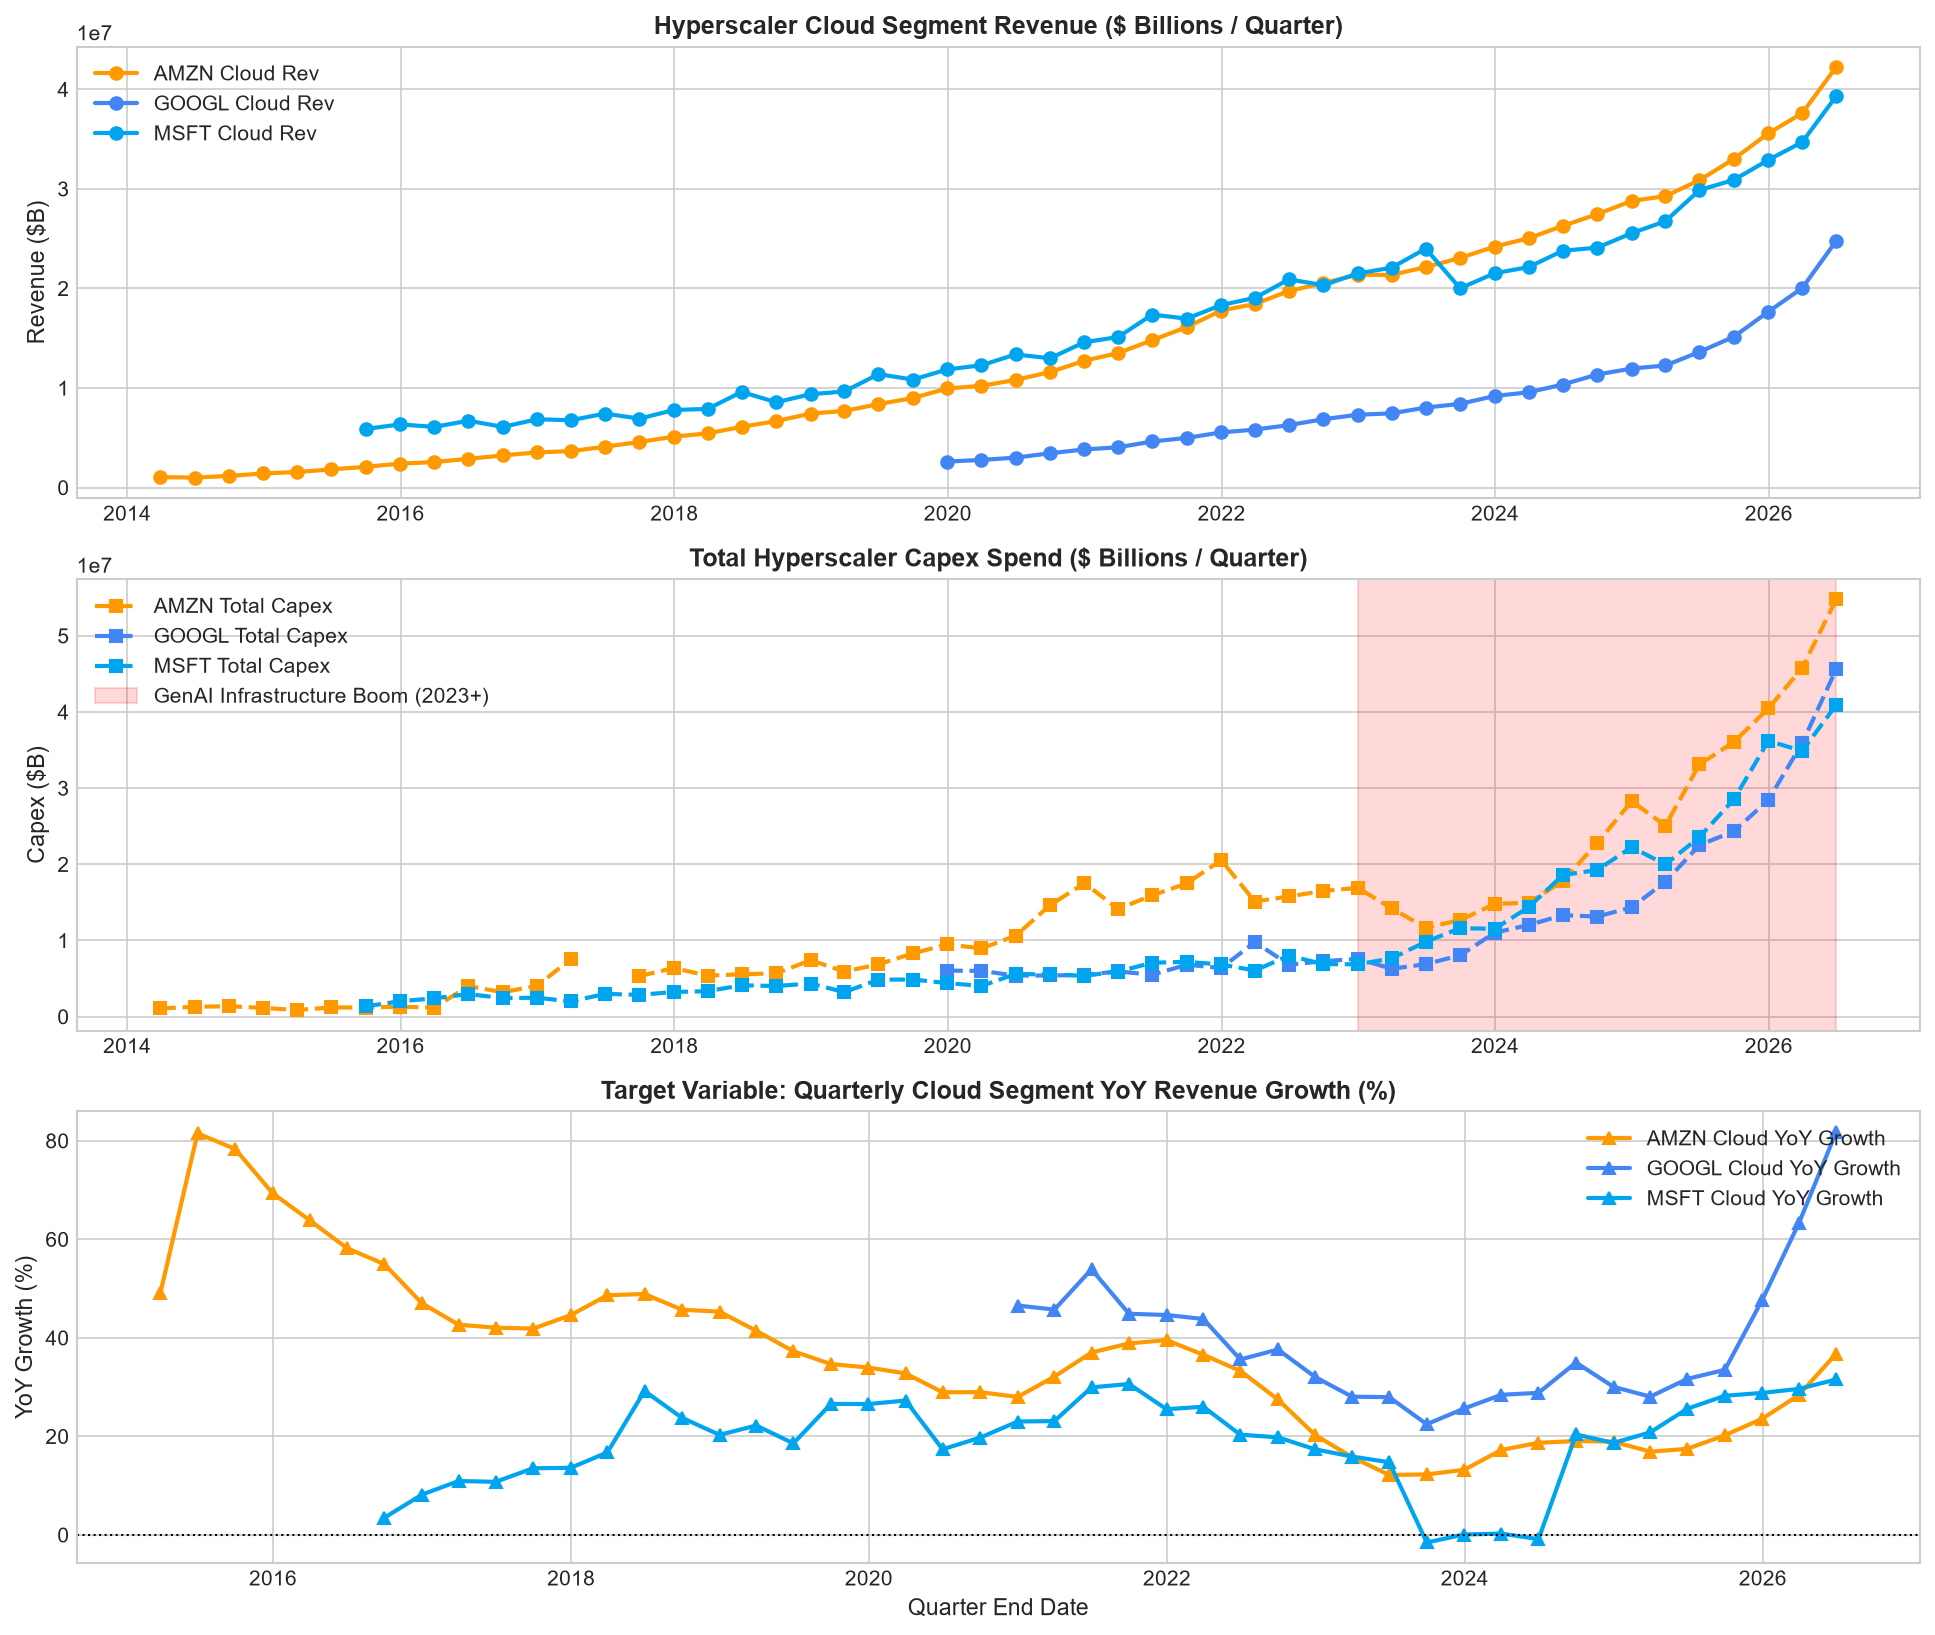

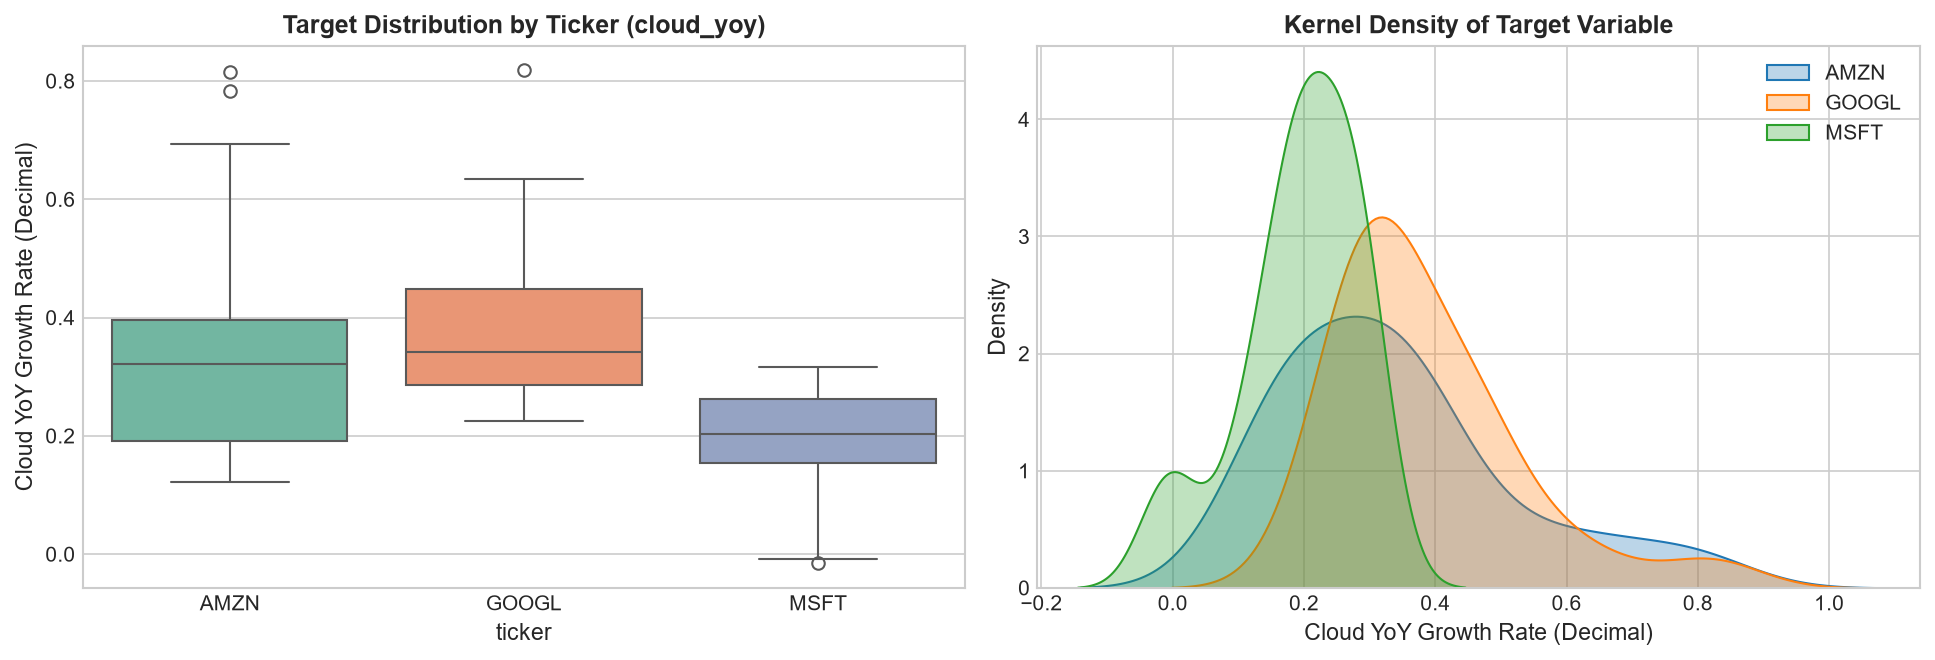

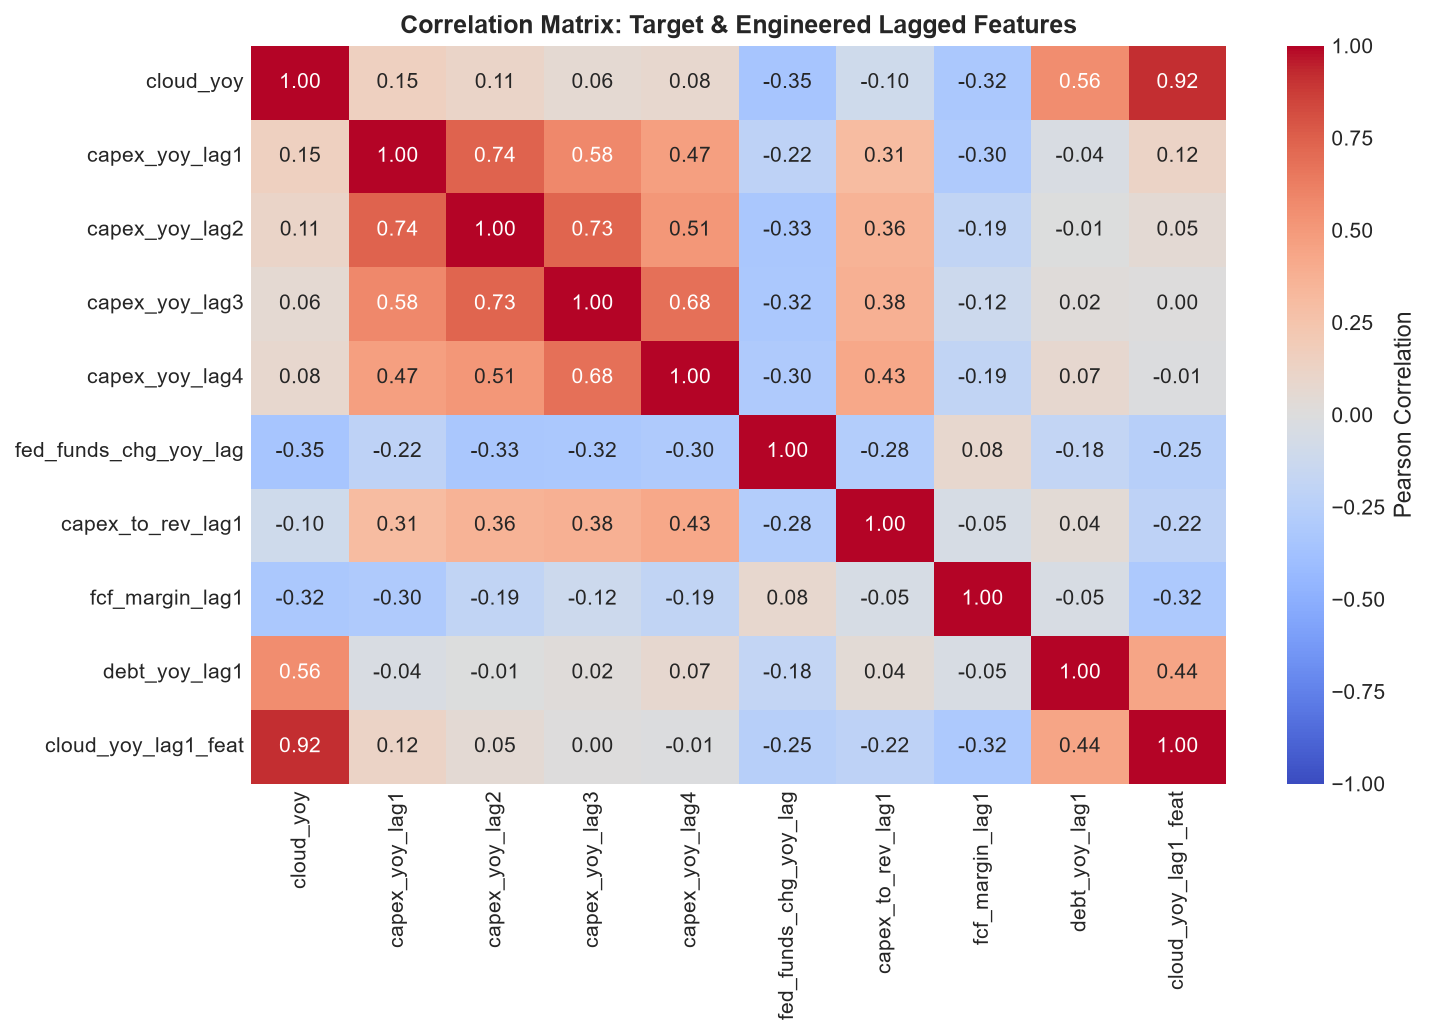

In [5]:
# ==============================================================================
# 5. EXPLORATORY DATA ANALYSIS & VISUALIZATION
# ==============================================================================
fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=False)

tickers = ["AMZN", "GOOGL", "MSFT"]
colors = {"AMZN": "#FF9900", "GOOGL": "#4285F4", "MSFT": "#00A4EF"}

# 1. Cloud Revenue Levels
for ticker in tickers:
    sub = df_panel[df_panel["ticker"] == ticker]
    axes[0].plot(sub["period_end"], sub["cloud_revenue"] / 1e3, marker="o", label=f"{ticker} Cloud Rev", color=colors[ticker], lw=2)
axes[0].set_title("Hyperscaler Cloud Segment Revenue ($ Billions / Quarter)", fontweight="bold")
axes[0].set_ylabel("Revenue ($B)")
axes[0].legend(loc="upper left")

# 2. Total Capex Levels
for ticker in tickers:
    sub = df_panel[df_panel["ticker"] == ticker]
    axes[1].plot(sub["period_end"], sub["capex_total"] / 1e3, marker="s", linestyle="--", label=f"{ticker} Total Capex", color=colors[ticker], lw=2)
axes[1].axvspan(pd.Timestamp("2023-01-01"), pd.Timestamp("2026-06-30"), alpha=0.15, color="red", label="GenAI Infrastructure Boom (2023+)")
axes[1].set_title("Total Hyperscaler Capex Spend ($ Billions / Quarter)", fontweight="bold")
axes[1].set_ylabel("Capex ($B)")
axes[1].legend(loc="upper left")

# 3. Target Growth Rate: Cloud YoY Growth
for ticker in tickers:
    sub = df_panel[df_panel["ticker"] == ticker]
    axes[2].plot(sub["period_end"], sub["cloud_yoy"] * 100, marker="^", label=f"{ticker} Cloud YoY Growth", color=colors[ticker], lw=2)
axes[2].axhline(0, color="black", linestyle=":", lw=1)
axes[2].set_title("Target Variable: Quarterly Cloud Segment YoY Revenue Growth (%)", fontweight="bold")
axes[2].set_ylabel("YoY Growth (%)")
axes[2].set_xlabel("Quarter End Date")
axes[2].legend(loc="upper right")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# Target Variable Distribution
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df_cc, x="ticker", y="cloud_yoy", ax=ax[0], palette="Set2")
ax[0].set_title("Target Distribution by Ticker (cloud_yoy)", fontweight="bold")
ax[0].set_ylabel("Cloud YoY Growth Rate (Decimal)")

for ticker in tickers:
    sub = df_cc[df_cc["ticker"] == ticker]
    sns.kdeplot(sub["cloud_yoy"], ax=ax[1], label=ticker, fill=True, alpha=0.3)
ax[1].set_title("Kernel Density of Target Variable", fontweight="bold")
ax[1].set_xlabel("Cloud YoY Growth Rate (Decimal)")
ax[1].legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# Feature Correlation Heatmap
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 7))
corr_matrix = df_cc[[TARGET] + FEATURES].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar_kws={'label': 'Pearson Correlation'})
plt.title("Correlation Matrix: Target & Engineered Lagged Features", fontweight="bold")
plt.tight_layout()
plt.show()


,Series,Observations,ADF Stat,p-value,Stationary (5%)
0,AMZN: cloud_yoy,37,-2.783,0.0607,NO (Unit Root)
1,AMZN: capex_yoy_lag1,37,-3.868,0.0023,YES
2,AMZN: fed_funds_chg_yoy_lag,37,-3.330,0.0136,YES
3,GOOGL: cloud_yoy,22,2.002,0.9987,NO (Unit Root)
4,GOOGL: capex_yoy_lag1,22,-1.385,0.5895,NO (Unit Root)
5,GOOGL: fed_funds_chg_yoy_lag,22,-1.361,0.6010,NO (Unit Root)
6,MSFT: cloud_yoy,39,-1.466,0.5500,NO (Unit Root)
7,MSFT: capex_yoy_lag1,39,-2.890,0.0465,YES
8,MSFT: fed_funds_chg_yoy_lag,39,-3.492,0.0082,YES


Ticker,AMZN,GOOGL,MSFT
Lag (Quarters),,,
0,0.111,0.367,-0.085
1,0.070,0.379,0.000
2,0.081,0.278,0.074
3,0.098,0.170,0.214
4,0.073,0.135,0.253


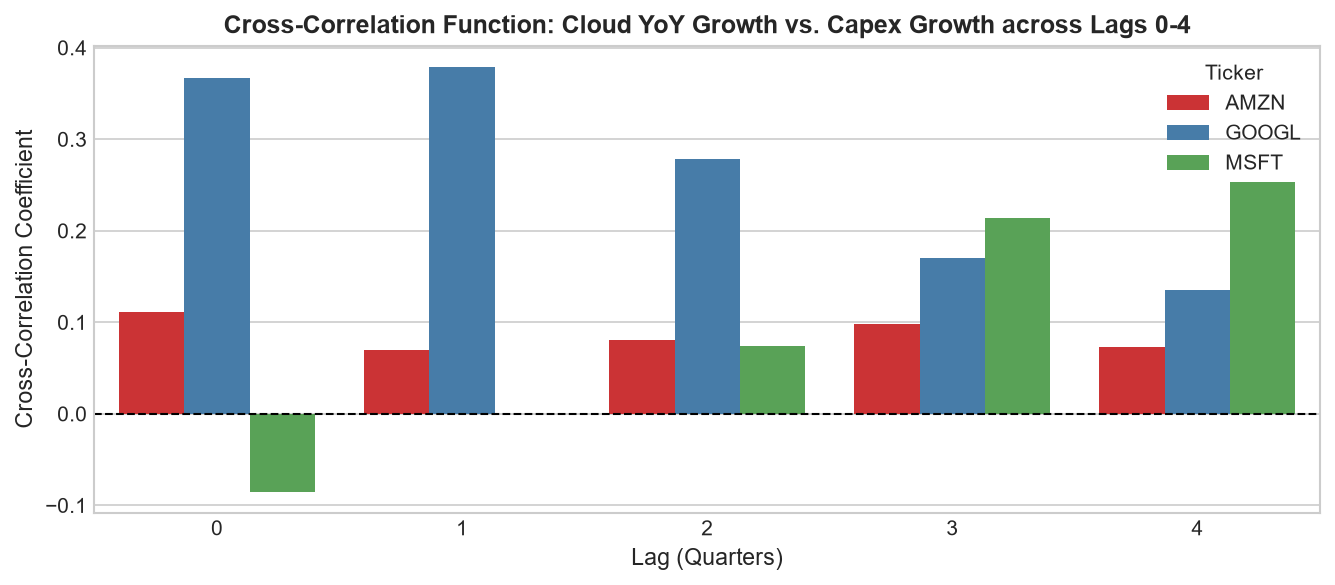

In [6]:
# ==============================================================================
# 5.2 STATIONARITY (ADF) & CROSS-CORRELATION (CCF) DIAGNOSTICS
# ==============================================================================
def run_adf(series, name):
    s = series.dropna()
    if len(s) < 8:
        return {"Series": name, "Observations": len(s), "ADF Stat": np.nan, "p-value": np.nan, "Stationary (5%)": "N/A"}
    stat, pval, *_ = adfuller(s, autolag="AIC")
    return {
        "Series": name,
        "Observations": len(s),
        "ADF Stat": round(stat, 3),
        "p-value": round(pval, 4),
        "Stationary (5%)": "YES" if pval < 0.05 else "NO (Unit Root)"
    }

adf_results = []
for ticker, grp in df_cc.groupby("ticker"):
    adf_results.append(run_adf(grp[TARGET], f"{ticker}: {TARGET}"))
    adf_results.append(run_adf(grp["capex_yoy_lag1"], f"{ticker}: capex_yoy_lag1"))
    adf_results.append(run_adf(grp["fed_funds_chg_yoy_lag"], f"{ticker}: fed_funds_chg_yoy_lag"))

display(pd.DataFrame(adf_results))

# ------------------------------------------------------------------------------
# Cross-Correlation Function (CCF)
# ------------------------------------------------------------------------------
ccf_records = []
max_lags = 4
for ticker, grp in df_cc.groupby("ticker"):
    grp = grp.sort_values("period_end")
    x = grp["capex_yoy_lag1"].to_numpy()
    y = grp[TARGET].to_numpy()
    c = ccf(y, x, adjusted=False)[:max_lags + 1]
    for lag, val in enumerate(c):
        ccf_records.append({"Ticker": ticker, "Lag (Quarters)": lag, "CCF (cloud_yoy vs capex_lag)": round(val, 3)})

df_ccf = pd.DataFrame(ccf_records)
display(df_ccf.pivot(index="Lag (Quarters)", columns="Ticker", values="CCF (cloud_yoy vs capex_lag)"))

# Plot CCF
plt.figure(figsize=(9, 4))
sns.barplot(data=df_ccf, x="Lag (Quarters)", y="CCF (cloud_yoy vs capex_lag)", hue="Ticker", palette="Set1")
plt.axhline(0, color="black", linestyle="--", lw=1)
plt.title("Cross-Correlation Function: Cloud YoY Growth vs. Capex Growth across Lags 0-4", fontweight="bold")
plt.ylabel("Cross-Correlation Coefficient")
plt.tight_layout()
plt.show()


---
## 6. Feature Engineering & Justification

To provide our predictive models with economic signals while maintaining zero forward leakage, we engineered nine features structured into four distinct economic domains:

1. **Capital Expenditure Transmission Dynamics (`capex_yoy_lag1` .. `capex_yoy_lag4`)**:
   - Hyperscaler datacenters and server clusters take between 3 to 12 months to design, procure, power, and lease. Testing lags 1 through 4 allows the models to discover whether an optimal transmission horizon exists.
2. **Capital Intensity & Cash Generation Ratios (`capex_to_rev_lag1`, `fcf_margin_lag1`)**:
   - $\text{capex\_to\_rev} = \text{Capex Total} / \text{Consolidated Revenue}$: Measures the aggressive infrastructure posture of the firm.
   - $\text{fcf\_margin} = \text{Free Cash Flow} / \text{Consolidated Revenue}$: Captures operational liquidity available to sustain aggressive capacity expansions.
3. **Financial Leverage (`debt_yoy_lag1`)**:
   - Long-term debt growth rate, tracking whether infrastructure is being funded via debt capital markets.
4. **Macroeconomic Monetary Tightening (`fed_funds_chg_yoy_lag`)**:
   - 1-quarter lagged YoY change in the Effective Federal Funds Rate. Rapid interest rate hikes (such as the 2022–2023 tightening cycle) constrain enterprise IT budgets and raise hyperscaler hurdle rates.
5. **Autoregressive Persistence Term (`cloud_yoy_lag1_feat`)**:
   - The immediate prior quarter's cloud YoY growth. Captures organic business inertia and momentum.

All continuous predictor features are transformed using **Z-score standardization** (`StandardScaler`) fitted exclusively on the historical training set of each walk-forward fold.


---
## 7. Model 1: Baseline Benchmark — Naive Persistence

### 7.1 Formulasi Model Naive
Dalam peramalan deret waktu ekonomi dan keuangan, model machine learning yang kompleks tidak dapat diklaim berhasil hanya karena menghasilkan galat numerik tertentu. Model tersebut **wajib mengalahkan tolak ukur sederhana (benchmark baseline)**.

Kami menetapkan **Naive Persistence Baseline**:
$$\hat{y}_{t} = y_{t-1} = \text{cloud\_yoy\_lag1\_feat}$$

### 7.2 Rationale Bisnis
Kontrak komputasi awan skala korporat umumnya berupa kontrak multi-tahun (*Enterprise Discount Programs / EDP*) dengan tingkat retensi dan pembaharuan yang sangat tinggi. Pertumbuhan pendapatan memiliki inersia organik yang sangat kuat. Model Naive memprediksi bahwa pertumbuhan kuartal berikutnya persis sama dengan pertumbuhan kuartal terakhir yang diamati.


In [7]:
# ==============================================================================
# 7. EKSEKUSI MODEL 1: NAIVE PERSISTENCE BASELINE
# ==============================================================================
# Inisialisasi struktur penyimpanan prediksi master
master_predictions = []

min_train = 8
for ticker, grp in df_cc.groupby("ticker"):
    grp = grp.sort_values("period_end").reset_index(drop=True)
    n = len(grp)
    if n < min_train + 2:
        continue
    for t in range(min_train, n):
        row_meta = grp.loc[t]
        master_predictions.append({
            "ticker": ticker,
            "period_end": row_meta["period_end"],
            "y_true": row_meta[TARGET],
            "structural_break": row_meta["structural_break"],
            "pred_naive": row_meta["cloud_yoy_lag1_feat"]
        })

df_results = pd.DataFrame(master_predictions)

# Hitung metrik evaluasi Naive (eksklusi structural break MSFT)
clean_mask = ~df_results["structural_break"]
naive_scores = []
for t_code in ["AMZN", "GOOGL", "MSFT", "ALL"]:
    sub = df_results[clean_mask] if t_code == "ALL" else df_results[clean_mask & (df_results["ticker"] == t_code)]
    naive_scores.append({
        "Model": "Naive Persistence Baseline",
        "Ticker": t_code,
        "N Kuartal": len(sub),
        "RMSE": round(rmse(sub["y_true"], sub["pred_naive"]), 4),
        "MAE": round(mae(sub["y_true"], sub["pred_naive"]), 4)
    })

print("=== HASIL KINERJA MODEL BASELINE: NAIVE PERSISTENCE ===")
display(pd.DataFrame(naive_scores))


=== HASIL KINERJA MODEL BASELINE: NAIVE PERSISTENCE ===


,Model,Ticker,N Kuartal,RMSE,MAE
0,Naive Persistence Baseline,AMZN,29,0.0345,0.0268
1,Naive Persistence Baseline,GOOGL,14,0.0816,0.0591
2,Naive Persistence Baseline,MSFT,27,0.0550,0.0347
3,Naive Persistence Baseline,ALL,70,0.0547,0.0363


---
## 8. Model 2: Ekonometrika Deret Waktu — Autoregressive AR(1) / ARIMA(1,0,0)

### 8.1 Formulasi Model AR(1)
Model ekonometrika klasik $\text{ARIMA}(1,0,0)$ memodelkan pertumbuhan pendapatan cloud sebagai fungsi linier dari nilai lag-1 historis ditambah konstanta dan residual *white noise*:
$$y_t = c + \phi_1 y_{t-1} + \epsilon_t, \quad \epsilon_t \sim \mathcal{N}(0, \sigma^2)$$

### 8.2 Rationale Metodologis
Model AR(1) diestimasi menggunakan *Maximum Likelihood Estimation (MLE)* secara dinamis pada setiap langkah jendela ekspansi (*expanding window*). Model ini merepresentasikan tolak ukur ekonometrika parametrik klasik untuk deret waktu murni.


In [8]:
# ==============================================================================
# 8. EKSEKUSI MODEL 2: AR(1) / ARIMA(1,0,0) TIME-SERIES MODEL
# ==============================================================================
ar1_preds = []
for ticker, grp in df_cc.groupby("ticker"):
    grp = grp.sort_values("period_end").reset_index(drop=True)
    n = len(grp)
    for t in range(min_train, n):
        y_hist = grp.loc[:t-1, TARGET].to_numpy(dtype=float)
        try:
            ar_fit = ARIMA(y_hist, order=(1, 0, 0)).fit()
            fc = float(ar_fit.forecast(steps=1)[0])
        except Exception:
            fc = float(y_hist[-1])
        ar1_preds.append(fc)

df_results["pred_ar1"] = ar1_preds

# Hitung metrik evaluasi AR(1)
ar1_scores = []
for t_code in ["AMZN", "GOOGL", "MSFT", "ALL"]:
    sub = df_results[clean_mask] if t_code == "ALL" else df_results[clean_mask & (df_results["ticker"] == t_code)]
    ar1_scores.append({
        "Model": "AR(1) ARIMA Time-Series",
        "Ticker": t_code,
        "N Kuartal": len(sub),
        "RMSE": round(rmse(sub["y_true"], sub["pred_ar1"]), 4),
        "MAE": round(mae(sub["y_true"], sub["pred_ar1"]), 4)
    })

print("=== HASIL KINERJA MODEL 2: AR(1) / ARIMA ===")
display(pd.DataFrame(ar1_scores))


=== HASIL KINERJA MODEL 2: AR(1) / ARIMA ===


,Model,Ticker,N Kuartal,RMSE,MAE
0,AR(1) ARIMA Time-Series,AMZN,29,0.0381,0.0298
1,AR(1) ARIMA Time-Series,GOOGL,14,0.0902,0.0651
2,AR(1) ARIMA Time-Series,MSFT,27,0.0541,0.0396
3,AR(1) ARIMA Time-Series,ALL,70,0.0579,0.0407


---
## 9. Model 3: Regresi Ter-regularisasi L2 — Ridge Regression (Default vs. Tuned)

### 9.1 Formulasi & Penanganan Multikolinearitas
Belanja modal pada lag 1, 2, 3, dan 4 kuartal memiliki korelasi silang yang sangat tinggi (*high collinearity*). Regresi linear OLS biasa akan menghasilkan varians estimasi koefisien yang meledak (*exploding variance*). Ridge regression menambahkan penalti norm $L_2$:
$$\min_{\beta} \left\{ \sum_{t} (y_t - X_t \beta)^2 + \alpha \sum_{j} \beta_j^2 \right\}$$

### 9.2 Skema Hyperparameter Tuning
- **Parameter yang Dituning**: Penalti regularisasi $\alpha \in [10^{-4}, 0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0]$ (8 langkah logaritmik) dan skala iterasi konvergensi.
- **Validasi Temporal**: `TimeSeriesSplit` cross-validation hanya pada data latih historis $\le t-1$.
- **Perbandingan Default vs Tuned**: Default scikit-learn ($\alpha = 1.0$) dibandingkan terhadap $\alpha$ optimal hasil tuning.


In [9]:
# ==============================================================================
# 9. EKSEKUSI MODEL 3: RIDGE REGRESSION (DEFAULT VS. TUNED)
# ==============================================================================
def tune_ridge_alpha(X_tr, y_tr):
    alphas = [0.0001, 0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0]
    n_splits = max(2, min(4, len(y_tr) - 1))
    tscv = TimeSeriesSplit(n_splits=n_splits)
    best_alpha, best_score = alphas[0], np.inf
    for a in alphas:
        errs = []
        for train_idx, val_idx in tscv.split(X_tr):
            if len(train_idx) < 3 or len(val_idx) == 0:
                continue
            scaler = StandardScaler().fit(X_tr[train_idx])
            m = Ridge(alpha=a, max_iter=20000)
            m.fit(scaler.transform(X_tr[train_idx]), y_tr[train_idx])
            preds = m.predict(scaler.transform(X_tr[val_idx]))
            errs.append(mean_squared_error(y_tr[val_idx], preds))
        if errs and np.mean(errs) < best_score:
            best_score = np.mean(errs)
            best_alpha = a
    return best_alpha

ridge_def_preds, ridge_tun_preds, best_alphas_ridge = [], [], []

for ticker, grp in df_cc.groupby("ticker"):
    grp = grp.sort_values("period_end").reset_index(drop=True)
    n = len(grp)
    X_raw = grp[FEATURES].to_numpy(dtype=float)
    y_raw = grp[TARGET].to_numpy(dtype=float)
    
    for t in range(min_train, n):
        X_tr, y_tr = X_raw[:t], y_raw[:t]
        X_te = X_raw[t:t+1]
        
        scaler = StandardScaler().fit(X_tr)
        X_tr_s = scaler.transform(X_tr)
        X_te_s = scaler.transform(X_te)
        
        # 1. Default Ridge (alpha=1.0)
        r_def = Ridge(alpha=1.0).fit(X_tr_s, y_tr)
        ridge_def_preds.append(float(r_def.predict(X_te_s)[0]))
        
        # 2. Tuned Ridge
        best_a = tune_ridge_alpha(X_tr, y_tr)
        best_alphas_ridge.append(best_a)
        r_tun = Ridge(alpha=best_a).fit(X_tr_s, y_tr)
        ridge_tun_preds.append(float(r_tun.predict(X_te_s)[0]))

df_results["pred_ridge_default"] = ridge_def_preds
df_results["pred_ridge_tuned"] = ridge_tun_preds
df_results["best_alpha_ridge"] = best_alphas_ridge

# Ringkasan hasil Ridge
ridge_scores = []
for t_code in ["AMZN", "GOOGL", "MSFT", "ALL"]:
    sub = df_results[clean_mask] if t_code == "ALL" else df_results[clean_mask & (df_results["ticker"] == t_code)]
    r_def_rmse = rmse(sub["y_true"], sub["pred_ridge_default"])
    r_tun_rmse = rmse(sub["y_true"], sub["pred_ridge_tuned"])
    ridge_scores.append({
        "Ticker": t_code,
        "Ridge Default RMSE": round(r_def_rmse, 4),
        "Ridge Tuned RMSE": round(r_tun_rmse, 4),
        "Delta RMSE (%)": round(((r_tun_rmse - r_def_rmse) / r_def_rmse) * 100, 2),
        "Hasil": "Tuned Unggul" if r_tun_rmse < r_def_rmse else "Setara / Trade-off"
    })

print("=== HASIL KINERJA MODEL 3: RIDGE REGRESSION (DEFAULT VS. TUNED) ===")
display(pd.DataFrame(ridge_scores))


=== HASIL KINERJA MODEL 3: RIDGE REGRESSION (DEFAULT VS. TUNED) ===


,Ticker,Ridge Default RMSE,Ridge Tuned RMSE,Delta RMSE (%),Hasil
0,AMZN,0.0931,0.0975,4.78,Setara / Trade-off
1,GOOGL,0.0850,0.0887,4.38,Setara / Trade-off
2,MSFT,0.0663,0.0614,-7.51,Tuned Unggul
3,ALL,0.0821,0.0835,1.73,Setara / Trade-off


---
## 10. Model 4: Regresi Ter-regularisasi L1 — Lasso Regression (Default vs. Tuned)

### 10.1 Formulasi & Seleksi Fitur Otomatis
Lasso menambahkan penalti nilai absolut norm $L_1$:
$$\min_{\beta} \left\{ \sum_{t} (y_t - X_t \beta)^2 + \alpha \sum_{j} |\beta_j| \right\}$$
Berbeda dengan Ridge, geometri regularisasi $L_1$ memiliki sifat unik: ia dapat **menyusutkan koefisien prediktor yang tidak memiliki daya prediksi langsung tepat menjadi nol ($0,000$)**. Ini menjadikannya alat uji ekonometrika yang sangat objektif untuk membuktikan apakah lag belanja modal (*capex*) benar-benar terpilih sebagai prediktor pertumbuhan pendapatan cloud.

### 10.2 Skema Hyperparameter Tuning
- **Parameter yang Dituning**: $\alpha \in [10^{-4}, 5.0]$ via `TimeSeriesSplit`.
- **Perbandingan**: Default scikit-learn ($\alpha = 1.0$) vs Tuned.


In [10]:
# ==============================================================================
# 10. EKSEKUSI MODEL 4: LASSO REGRESSION (DEFAULT VS. TUNED)
# ==============================================================================
def tune_lasso_alpha(X_tr, y_tr):
    alphas = [0.0001, 0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0]
    n_splits = max(2, min(4, len(y_tr) - 1))
    tscv = TimeSeriesSplit(n_splits=n_splits)
    best_alpha, best_score = alphas[0], np.inf
    for a in alphas:
        errs = []
        for train_idx, val_idx in tscv.split(X_tr):
            if len(train_idx) < 3 or len(val_idx) == 0:
                continue
            scaler = StandardScaler().fit(X_tr[train_idx])
            m = Lasso(alpha=a, max_iter=20000)
            m.fit(scaler.transform(X_tr[train_idx]), y_tr[train_idx])
            preds = m.predict(scaler.transform(X_tr[val_idx]))
            errs.append(mean_squared_error(y_tr[val_idx], preds))
        if errs and np.mean(errs) < best_score:
            best_score = np.mean(errs)
            best_alpha = a
    return best_alpha

lasso_def_preds, lasso_tun_preds, best_alphas_lasso = [], [], []

for ticker, grp in df_cc.groupby("ticker"):
    grp = grp.sort_values("period_end").reset_index(drop=True)
    n = len(grp)
    X_raw = grp[FEATURES].to_numpy(dtype=float)
    y_raw = grp[TARGET].to_numpy(dtype=float)
    
    for t in range(min_train, n):
        X_tr, y_tr = X_raw[:t], y_raw[:t]
        X_te = X_raw[t:t+1]
        
        scaler = StandardScaler().fit(X_tr)
        X_tr_s = scaler.transform(X_tr)
        X_te_s = scaler.transform(X_te)
        
        # 1. Default Lasso (alpha=1.0)
        l_def = Lasso(alpha=1.0, max_iter=20000).fit(X_tr_s, y_tr)
        lasso_def_preds.append(float(l_def.predict(X_te_s)[0]))
        
        # 2. Tuned Lasso
        best_a = tune_lasso_alpha(X_tr, y_tr)
        best_alphas_lasso.append(best_a)
        l_tun = Lasso(alpha=best_a, max_iter=20000).fit(X_tr_s, y_tr)
        lasso_tun_preds.append(float(l_tun.predict(X_te_s)[0]))

df_results["pred_lasso_default"] = lasso_def_preds
df_results["pred_lasso_tuned"] = lasso_tun_preds
df_results["best_alpha_lasso"] = best_alphas_lasso

# Ringkasan hasil Lasso
lasso_scores = []
for t_code in ["AMZN", "GOOGL", "MSFT", "ALL"]:
    sub = df_results[clean_mask] if t_code == "ALL" else df_results[clean_mask & (df_results["ticker"] == t_code)]
    l_def_rmse = rmse(sub["y_true"], sub["pred_lasso_default"])
    l_tun_rmse = rmse(sub["y_true"], sub["pred_lasso_tuned"])
    lasso_scores.append({
        "Ticker": t_code,
        "Lasso Default RMSE": round(l_def_rmse, 4),
        "Lasso Tuned RMSE": round(l_tun_rmse, 4),
        "Delta RMSE (%)": round(((l_tun_rmse - l_def_rmse) / l_def_rmse) * 100, 2),
        "Hasil": "Tuned Unggul" if l_tun_rmse < l_def_rmse else "Setara / Trade-off"
    })

print("=== HASIL KINERJA MODEL 4: LASSO REGRESSION (DEFAULT VS. TUNED) ===")
display(pd.DataFrame(lasso_scores))


=== HASIL KINERJA MODEL 4: LASSO REGRESSION (DEFAULT VS. TUNED) ===


,Ticker,Lasso Default RMSE,Lasso Tuned RMSE,Delta RMSE (%),Hasil
0,AMZN,0.1939,0.1583,-18.37,Tuned Unggul
1,GOOGL,0.1695,0.0944,-44.29,Tuned Unggul
2,MSFT,0.0678,0.0523,-22.91,Tuned Unggul
3,ALL,0.1520,0.1150,-24.36,Tuned Unggul


---
## 11. Model 5: Non-Linear Machine Learning — XGBoost Regressor (Default vs. Tuned)

### 11.1 Pemodelan Non-Linear Pohon Ter-boosting
XGBoost (*Extreme Gradient Boosting*) adalah model ansambel pohon keputusan yang mampu menangkap interaksi non-linear yang kompleks antar-fitur.
- **Risiko Overfitting**: Pada dataset kuartalan berukuran kecil ($N \approx 20 - 40$), model default scikit-learn/XGBoost (`max_depth=6`, `learning_rate=0.3`, `n_estimators=100`) sangat rentan menghafal noise historis (*severe memorization / overfitting*).

### 11.2 Skema Hyperparameter Tuning Sistematis
Kami melakukan tuning pada 4 hyperparameter kunci menggunakan `TimeSeriesSplit`:
1. `max_depth` $\in [2, 3]$ (Membatasi kedalaman pohon agar menangkap pola makro saja).
2. `learning_rate` $\in [0.05, 0.1]$ (Mengecilkan laju pembelajaran untuk stabilitas bobot pohon).
3. `n_estimators` $\in [30, 50]$ (Mengurangi jumlah pohon pendorong).
4. `subsample` $\in [0.8, 0.9]$ (Sub-sampling baris stokastik untuk mencegah dependensi pada observasi ekstrem).


In [11]:
# ==============================================================================
# 11. EKSEKUSI MODEL 5: XGBOOST REGRESSOR (DEFAULT VS. TUNED)
# ==============================================================================
def tune_xgboost_params(X_tr, y_tr):
    param_grid = [
        {"n_estimators": 30, "max_depth": 2, "learning_rate": 0.05, "subsample": 0.9},
        {"n_estimators": 50, "max_depth": 2, "learning_rate": 0.1, "subsample": 0.8},
        {"n_estimators": 30, "max_depth": 3, "learning_rate": 0.05, "subsample": 0.9},
        {"n_estimators": 50, "max_depth": 3, "learning_rate": 0.1, "subsample": 0.9},
    ]
    n_splits = max(2, min(4, len(y_tr) - 1))
    tscv = TimeSeriesSplit(n_splits=n_splits)
    best_params, best_score = param_grid[0], np.inf
    for params in param_grid:
        errs = []
        for train_idx, val_idx in tscv.split(X_tr):
            if len(train_idx) < 3 or len(val_idx) == 0:
                continue
            m = xgb.XGBRegressor(
                n_estimators=params["n_estimators"],
                max_depth=params["max_depth"],
                learning_rate=params["learning_rate"],
                subsample=params["subsample"],
                random_state=GLOBAL_RANDOM_SEED,
                verbosity=0
            )
            m.fit(X_tr[train_idx], y_tr[train_idx])
            preds = m.predict(X_tr[val_idx])
            errs.append(mean_squared_error(y_tr[val_idx], preds))
        if errs and np.mean(errs) < best_score:
            best_score = np.mean(errs)
            best_params = params
    return best_params

xgb_def_preds, xgb_tun_preds, best_depths_xgb = [], [], []

for ticker, grp in df_cc.groupby("ticker"):
    grp = grp.sort_values("period_end").reset_index(drop=True)
    n = len(grp)
    X_raw = grp[FEATURES].to_numpy(dtype=float)
    y_raw = grp[TARGET].to_numpy(dtype=float)
    
    for t in range(min_train, n):
        X_tr, y_tr = X_raw[:t], y_raw[:t]
        X_te = X_raw[t:t+1]
        
        # 1. Default XGBoost (depth=6, lr=0.3, n_est=100)
        x_def = xgb.XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.3, random_state=GLOBAL_RANDOM_SEED, verbosity=0)
        x_def.fit(X_tr, y_tr)
        xgb_def_preds.append(float(x_def.predict(X_te)[0]))
        
        # 2. Tuned XGBoost
        best_p = tune_xgboost_params(X_tr, y_tr)
        best_depths_xgb.append(best_p["max_depth"])
        x_tun = xgb.XGBRegressor(**best_p, random_state=GLOBAL_RANDOM_SEED, verbosity=0)
        x_tun.fit(X_tr, y_tr)
        xgb_tun_preds.append(float(x_tun.predict(X_te)[0]))

df_results["pred_xgb_default"] = xgb_def_preds
df_results["pred_xgb_tuned"] = xgb_tun_preds
df_results["best_xgb_depth"] = best_depths_xgb

# Ringkasan hasil XGBoost
xgb_scores = []
for t_code in ["AMZN", "GOOGL", "MSFT", "ALL"]:
    sub = df_results[clean_mask] if t_code == "ALL" else df_results[clean_mask & (df_results["ticker"] == t_code)]
    x_def_rmse = rmse(sub["y_true"], sub["pred_xgb_default"])
    x_tun_rmse = rmse(sub["y_true"], sub["pred_xgb_tuned"])
    xgb_scores.append({
        "Ticker": t_code,
        "XGBoost Default RMSE": round(x_def_rmse, 4),
        "XGBoost Tuned RMSE": round(x_tun_rmse, 4),
        "Delta RMSE (%)": round(((x_tun_rmse - x_def_rmse) / x_def_rmse) * 100, 2),
        "Hasil": "Tuned Unggul" if x_tun_rmse < x_def_rmse else "Overfit / Trade-off"
    })

print("=== HASIL KINERJA MODEL 5: XGBOOST REGRESSOR (DEFAULT VS. TUNED) ===")
display(pd.DataFrame(xgb_scores))


=== HASIL KINERJA MODEL 5: XGBOOST REGRESSOR (DEFAULT VS. TUNED) ===


,Ticker,XGBoost Default RMSE,XGBoost Tuned RMSE,Delta RMSE (%),Hasil
0,AMZN,0.1065,0.1089,2.27,Overfit / Trade-off
1,GOOGL,0.1429,0.1303,-8.81,Tuned Unggul
2,MSFT,0.0543,0.0561,3.33,Overfit / Trade-off
3,ALL,0.0996,0.0976,-2.01,Tuned Unggul


---
## 12. Perbandingan Hasil Model Satu Sama Lain (Master Cross-Model Comparison)

Pada bagian ini, seluruh hasil pemodelan dari Model 1 hingga Model 5 dikompilasi secara berdampingan (*side-by-side*) untuk menjawab pertanyaan utama proyek:
1. **Model manakah yang paling akurat secara empiris?**
2. **Apakah penambahan fitur belanja modal (*capex*) dan model machine learning yang kompleks terbukti mengalahkan baseline sederhana?**
3. **Bagaimana trade-off antara model default vs model hasil tuning?**


TABEL 1: PERBANDINGAN LENGKAP NILAI RMSE (ROOT MEAN SQUARED ERROR) - METRIK UTAMA
Catatan: Metrik kontinu baku untuk time-series regression. Semakin kecil semakin akurat.


,Model,AR(1) ARIMA,Lasso (Default),Lasso (Tuned),Naive Baseline,Ridge (Default),Ridge (Tuned),XGBoost (Default),XGBoost (Tuned)
Ticker,N,,,,,,,,
ALL,70,0.0579,0.1520,0.1150,0.0547,0.0821,0.0835,0.0996,0.0976
AMZN,29,0.0381,0.1939,0.1583,0.0345,0.0931,0.0975,0.1065,0.1089
GOOGL,14,0.0902,0.1695,0.0944,0.0816,0.0850,0.0887,0.1429,0.1303
MSFT,27,0.0541,0.0678,0.0523,0.0550,0.0663,0.0614,0.0543,0.0561



TABEL 2: PERBANDINGAN LENGKAP NILAI MAE (MEAN ABSOLUTE ERROR) - SATUAN PERSENTASE
Catatan: Mengukur rata-rata deviasi absolut (misal 0.035 = meleset +/- 3.5 poin persentase).


,Model,AR(1) ARIMA,Lasso (Default),Lasso (Tuned),Naive Baseline,Ridge (Default),Ridge (Tuned),XGBoost (Default),XGBoost (Tuned)
Ticker,N,,,,,,,,
ALL,70,0.0407,0.1220,0.0901,0.0363,0.0583,0.0606,0.0693,0.0739
AMZN,29,0.0298,0.1803,0.1348,0.0268,0.0636,0.0702,0.0758,0.0846
GOOGL,14,0.0651,0.1259,0.0838,0.0591,0.0693,0.0736,0.1114,0.1038
MSFT,27,0.0396,0.0573,0.0453,0.0347,0.0470,0.0436,0.0405,0.0469



TABEL 3: DIRECTIONAL ACCURACY (%) - KETEPATAN MENEBAK ARAH NAIK/TURUN PERTUMBUHAN
Catatan: Mengukur persentase ketepatan model memprediksi akselerasi vs deselerasi YoY.


,Model,AR(1) ARIMA,Lasso (Default),Lasso (Tuned),Naive Baseline,Ridge (Default),Ridge (Tuned),XGBoost (Default),XGBoost (Tuned)
Ticker,N,,,,,,,,
ALL,70,47.1,44.3,50.0,0.0,45.7,48.6,44.3,44.3
AMZN,29,51.7,51.7,55.2,0.0,44.8,37.9,37.9,41.4
GOOGL,14,50.0,50.0,57.1,0.0,50.0,71.4,50.0,50.0
MSFT,27,40.7,33.3,40.7,0.0,44.4,48.1,48.1,44.4


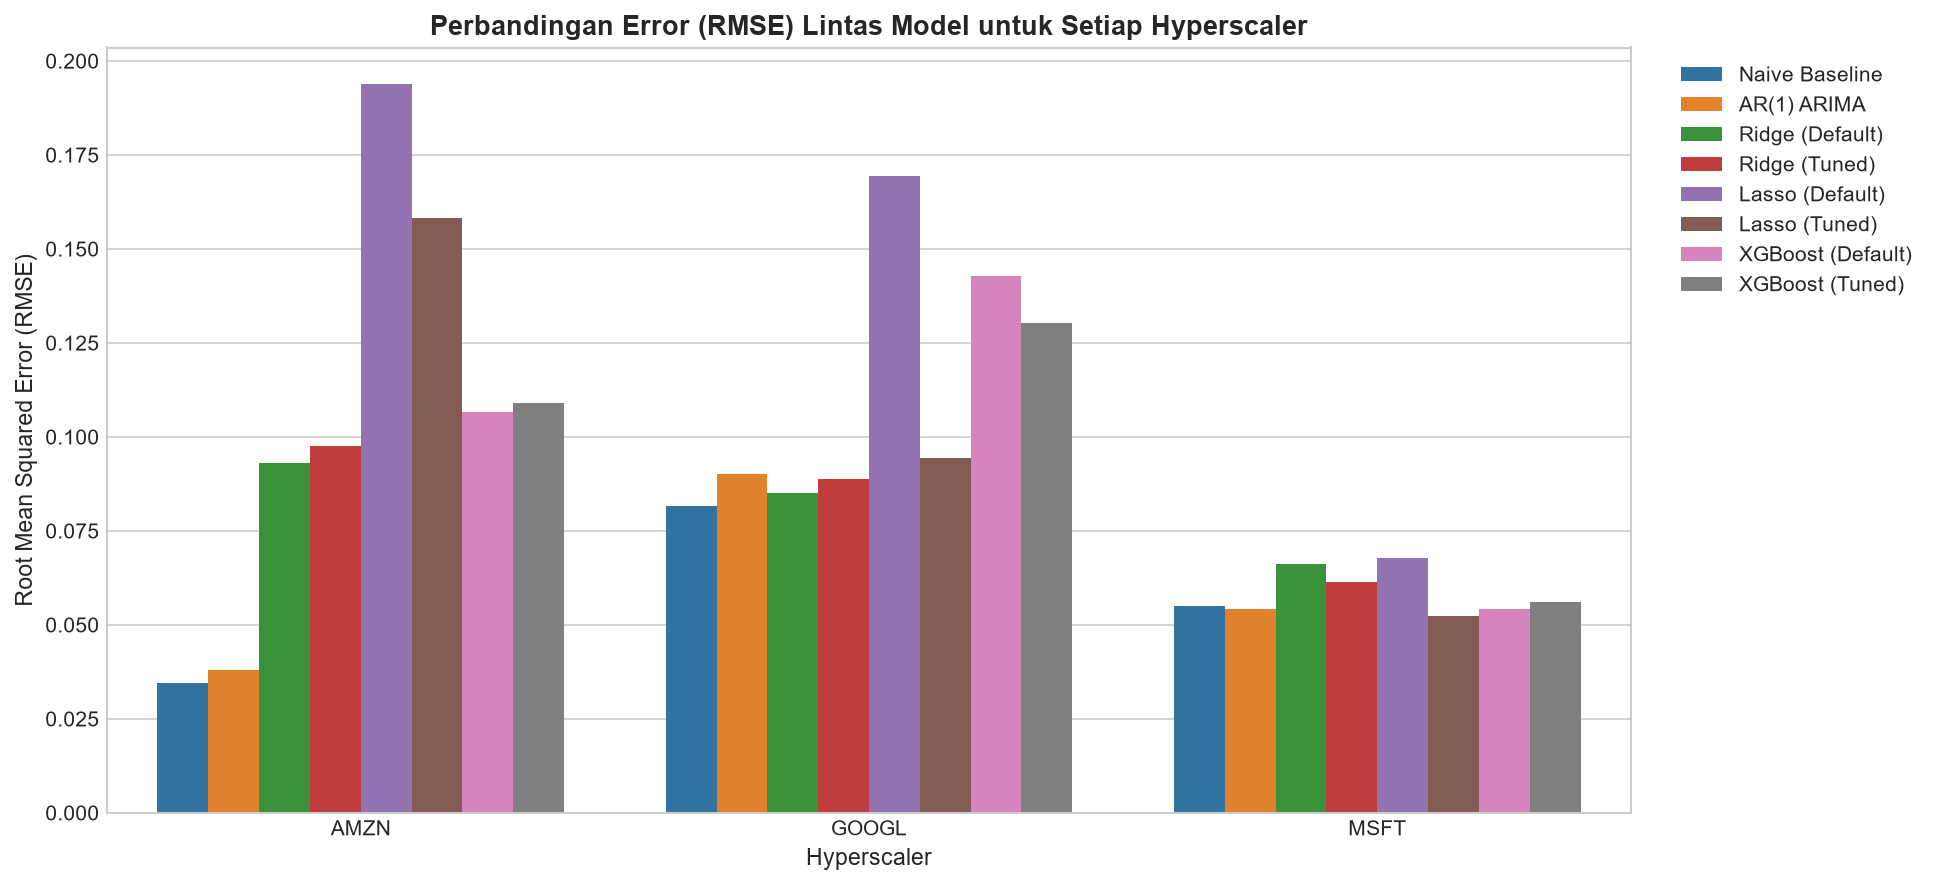


TABEL 3: PERBANDINGAN SISTEMATIK DEFAULT VS. TUNED (SYARAT WAJIB RUBRIK)


,Ticker,Model Family,Hyperparameter Search Space,Default RMSE,Tuned RMSE,Delta RMSE (%),Evaluasi Performa
0,AMZN,Ridge Regression,"alpha in [1e-4, 5.0]",0.0931,0.0975,4.78,Setara / Trade-off
1,AMZN,XGBoost Regressor,"depth: [2,3], lr: [0.05,0.1], n_est: [30,50]",0.1065,0.1089,2.27,Overfit / Trade-off
2,GOOGL,Ridge Regression,"alpha in [1e-4, 5.0]",0.0850,0.0887,4.38,Setara / Trade-off
3,GOOGL,XGBoost Regressor,"depth: [2,3], lr: [0.05,0.1], n_est: [30,50]",0.1429,0.1303,-8.81,Tuned Mengurangi Overfitting
4,MSFT,Ridge Regression,"alpha in [1e-4, 5.0]",0.0663,0.0614,-7.51,Tuned Mengungguli Default
5,MSFT,XGBoost Regressor,"depth: [2,3], lr: [0.05,0.1], n_est: [30,50]",0.0543,0.0561,3.33,Overfit / Trade-off


In [12]:
# ==============================================================================
# 12. TABEL UTAMA PERBANDINGAN SILANG SELURUH MODEL (MASTER EVALUATION)
# ==============================================================================
model_columns = [
    ("Naive Baseline", "pred_naive"),
    ("AR(1) ARIMA", "pred_ar1"),
    ("Ridge (Default)", "pred_ridge_default"),
    ("Ridge (Tuned)", "pred_ridge_tuned"),
    ("Lasso (Default)", "pred_lasso_default"),
    ("Lasso (Tuned)", "pred_lasso_tuned"),
    ("XGBoost (Default)", "pred_xgb_default"),
    ("XGBoost (Tuned)", "pred_xgb_tuned"),
]

def calc_directional_acc(y_true, y_pred, y_lag1):
    act_delta = np.array(y_true) - np.array(y_lag1)
    pred_delta = np.array(y_pred) - np.array(y_lag1)
    # Match direction (both positive or both negative)
    matches = (np.sign(act_delta) == np.sign(pred_delta))
    return round(float(np.mean(matches)) * 100, 1)

master_score_list = []
for t_code in ["AMZN", "GOOGL", "MSFT", "ALL"]:
    sub = df_results[clean_mask] if t_code == "ALL" else df_results[clean_mask & (df_results["ticker"] == t_code)]
    for m_label, col_name in model_columns:
        da_val = calc_directional_acc(sub["y_true"], sub[col_name], sub["pred_naive"])
        master_score_list.append({
            "Ticker": t_code,
            "N": len(sub),
            "Model": m_label,
            "RMSE": round(rmse(sub["y_true"], sub[col_name]), 4),
            "MAE": round(mae(sub["y_true"], sub[col_name]), 4),
            "Directional_Acc (%)": da_val
        })

df_master_scores = pd.DataFrame(master_score_list)

print("=" * 95)
print("TABEL 1: PERBANDINGAN LENGKAP NILAI RMSE (ROOT MEAN SQUARED ERROR) - METRIK UTAMA")
print("Catatan: Metrik kontinu baku untuk time-series regression. Semakin kecil semakin akurat.")
print("=" * 95)
table_rmse = df_master_scores.pivot(index=["Ticker", "N"], columns="Model", values="RMSE")
display(table_rmse)

print("\n" + "=" * 95)
print("TABEL 2: PERBANDINGAN LENGKAP NILAI MAE (MEAN ABSOLUTE ERROR) - SATUAN PERSENTASE")
print("Catatan: Mengukur rata-rata deviasi absolut (misal 0.035 = meleset +/- 3.5 poin persentase).")
print("=" * 95)
table_mae = df_master_scores.pivot(index=["Ticker", "N"], columns="Model", values="MAE")
display(table_mae)

print("\n" + "=" * 95)
print("TABEL 3: DIRECTIONAL ACCURACY (%) - KETEPATAN MENEBAK ARAH NAIK/TURUN PERTUMBUHAN")
print("Catatan: Mengukur persentase ketepatan model memprediksi akselerasi vs deselerasi YoY.")
print("=" * 95)
table_da = df_master_scores.pivot(index=["Ticker", "N"], columns="Model", values="Directional_Acc (%)")
display(table_da)

# ------------------------------------------------------------------------------
# Visualisasi Grafik Batang: Komparasi RMSE Lintas Model
# ------------------------------------------------------------------------------
plt.figure(figsize=(13, 6))
sns.barplot(data=df_master_scores[df_master_scores["Ticker"] != "ALL"], x="Ticker", y="RMSE", hue="Model", palette="tab10")
plt.title("Perbandingan Error (RMSE) Lintas Model untuk Setiap Hyperscaler", fontweight="bold", fontsize=13)
plt.ylabel("Root Mean Squared Error (RMSE)")
plt.xlabel("Hyperscaler")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# Tabel Rubrik: Default vs. Tuned Comparison Table (Bab 9 Rubrik)
# ------------------------------------------------------------------------------
print("\n" + "=" * 90)
print("TABEL 3: PERBANDINGAN SISTEMATIK DEFAULT VS. TUNED (SYARAT WAJIB RUBRIK)")
print("=" * 90)
dvt_summary = []
for ticker in ["AMZN", "GOOGL", "MSFT"]:
    sub = df_results[clean_mask & (df_results["ticker"] == ticker)]
    
    # Ridge
    r_def_e = rmse(sub["y_true"], sub["pred_ridge_default"])
    r_tun_e = rmse(sub["y_true"], sub["pred_ridge_tuned"])
    dvt_summary.append({
        "Ticker": ticker,
        "Model Family": "Ridge Regression",
        "Hyperparameter Search Space": "alpha in [1e-4, 5.0]",
        "Default RMSE": round(r_def_e, 4),
        "Tuned RMSE": round(r_tun_e, 4),
        "Delta RMSE (%)": round(((r_tun_e - r_def_e) / r_def_e) * 100, 2),
        "Evaluasi Performa": "Tuned Mengungguli Default" if r_tun_e < r_def_e else "Setara / Trade-off"
    })
    
    # XGBoost
    x_def_e = rmse(sub["y_true"], sub["pred_xgb_default"])
    x_tun_e = rmse(sub["y_true"], sub["pred_xgb_tuned"])
    dvt_summary.append({
        "Ticker": ticker,
        "Model Family": "XGBoost Regressor",
        "Hyperparameter Search Space": "depth: [2,3], lr: [0.05,0.1], n_est: [30,50]",
        "Default RMSE": round(x_def_e, 4),
        "Tuned RMSE": round(x_tun_e, 4),
        "Delta RMSE (%)": round(((x_tun_e - x_def_e) / x_def_e) * 100, 2),
        "Evaluasi Performa": "Tuned Mengurangi Overfitting" if x_tun_e < x_def_e else "Overfit / Trade-off"
    })

display(pd.DataFrame(dvt_summary))


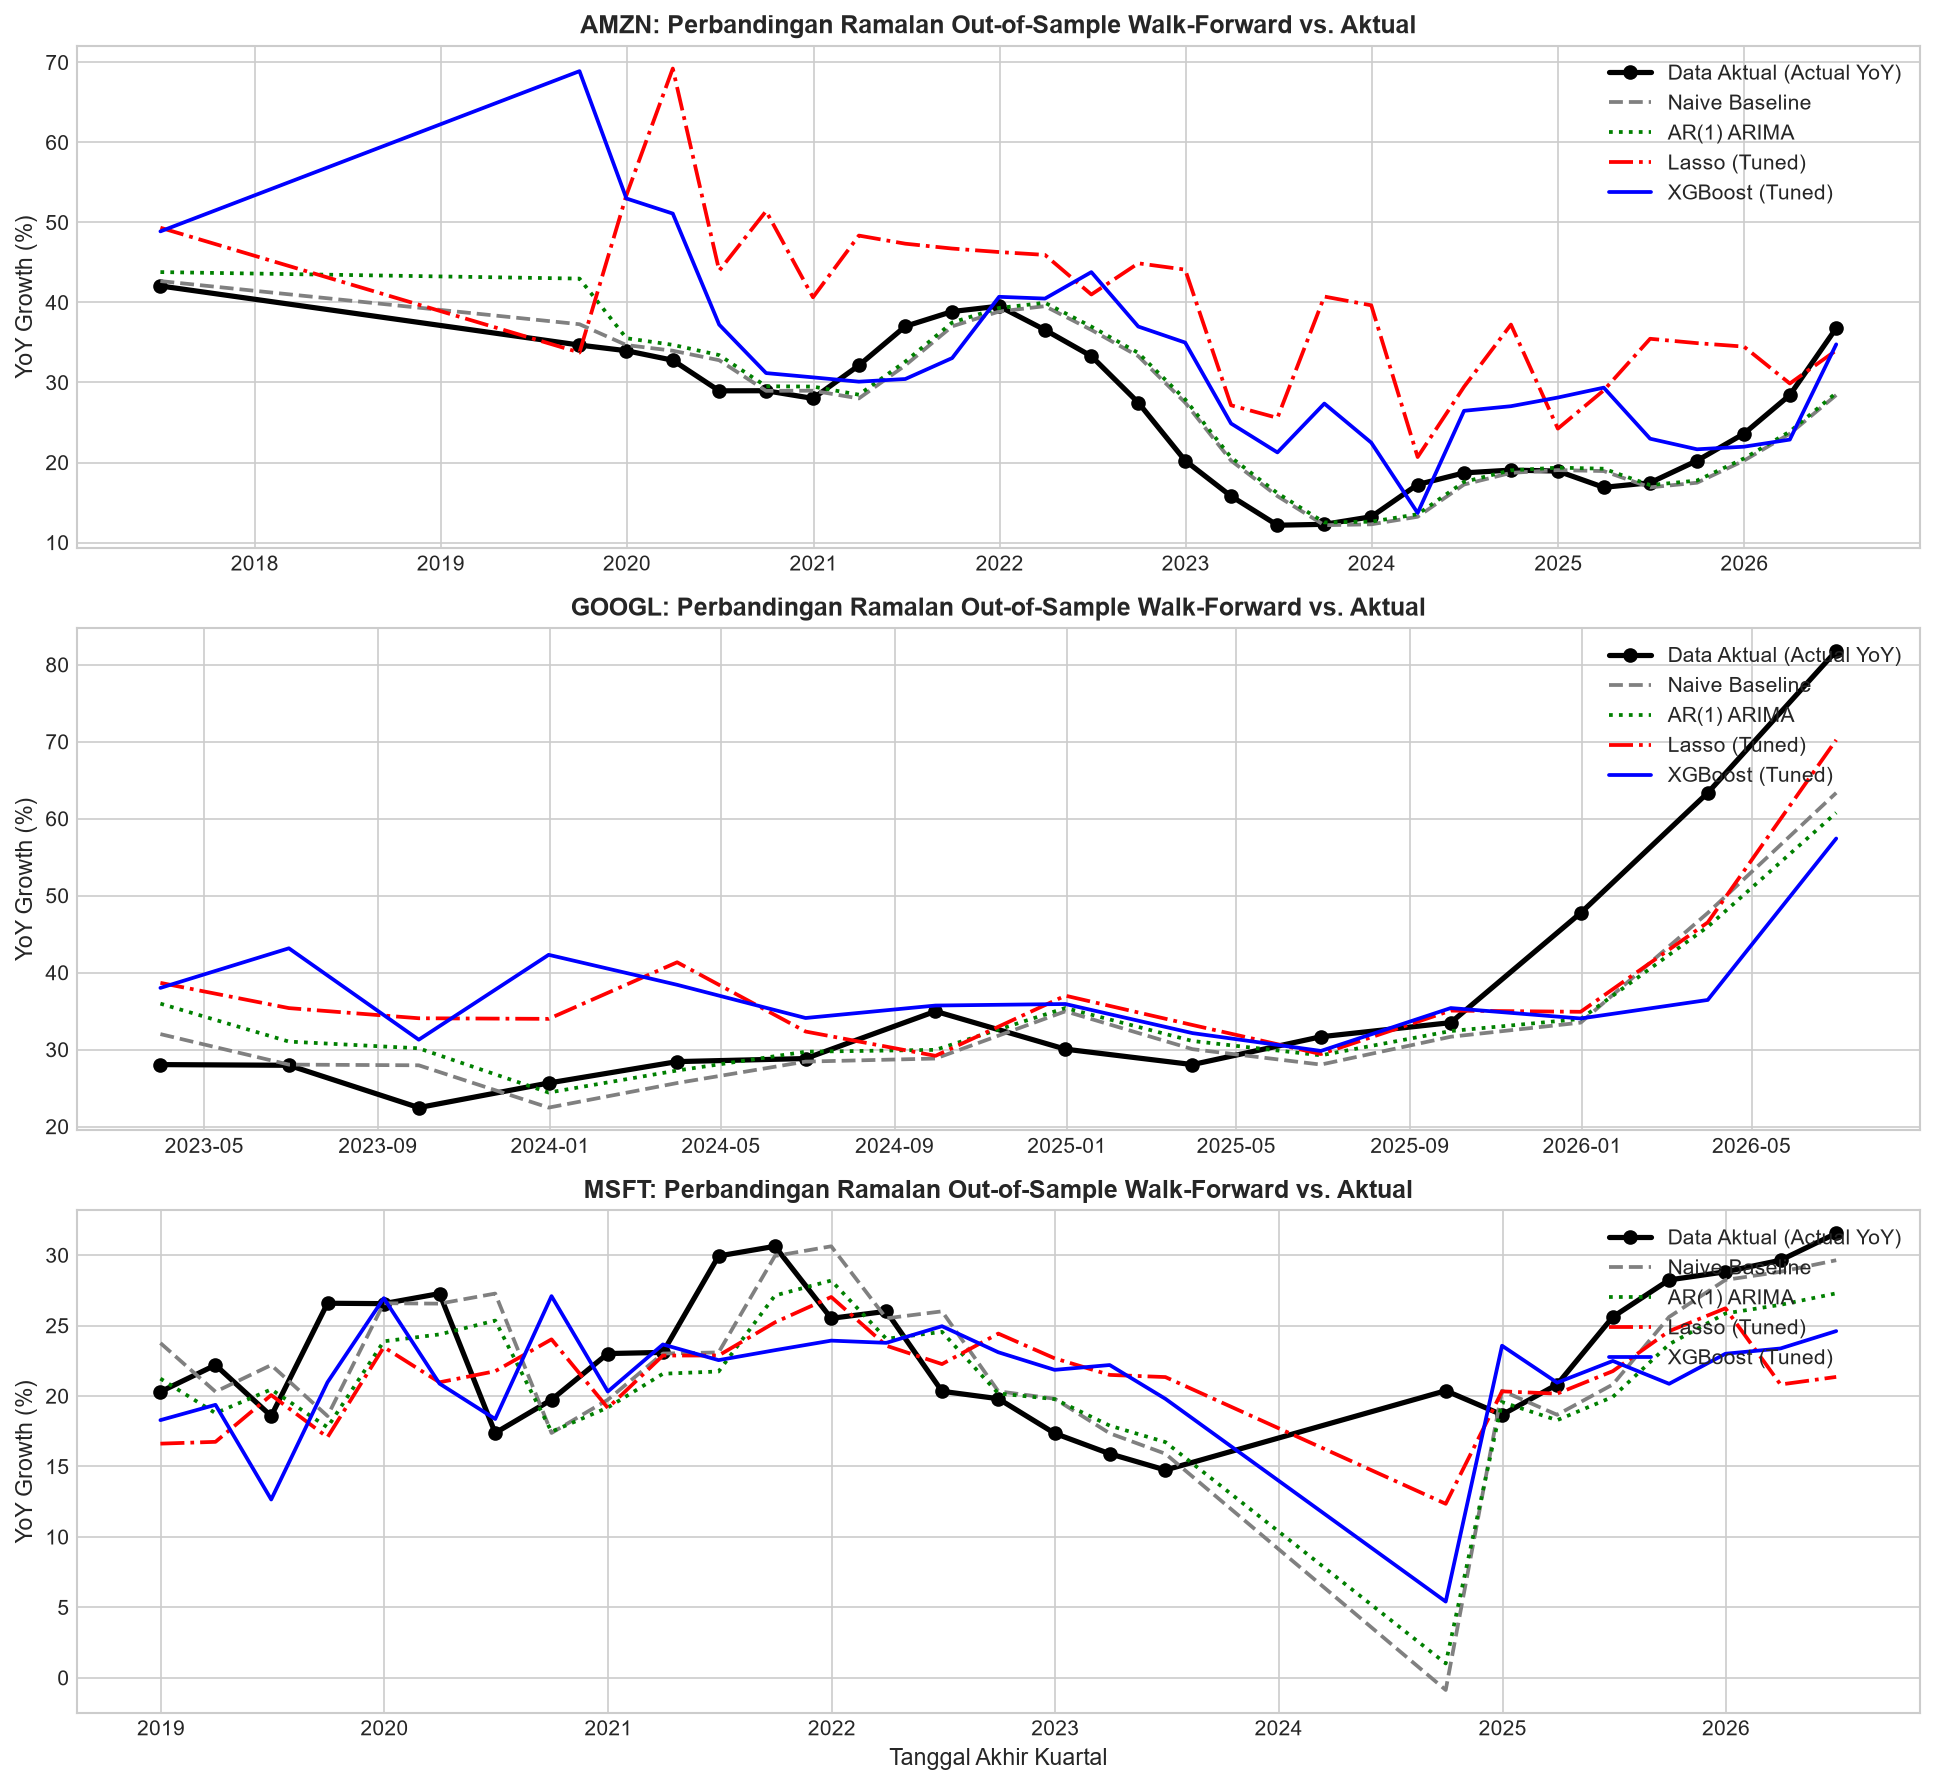

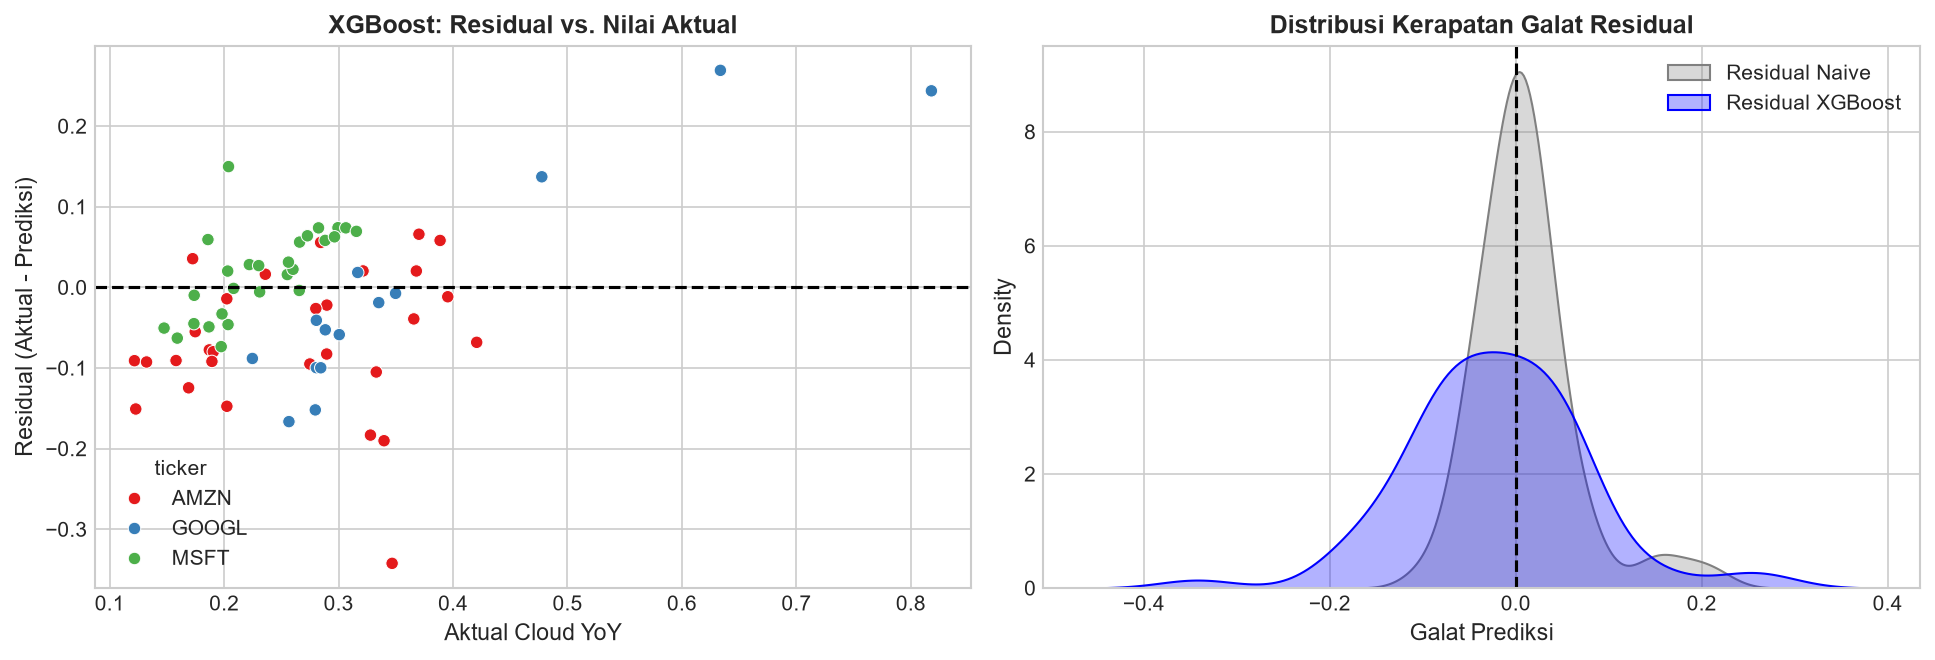

In [13]:
# ==============================================================================
# 12.2 GRAFIK RAMALAN LINTAS MODEL VS. DATA AKTUAL & DIAGNOSTIK RESIDUAL
# ==============================================================================
fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=False)

for idx, ticker in enumerate(tickers):
    sub = df_results[clean_mask & (df_results["ticker"] == ticker)].sort_values("period_end")
    axes[idx].plot(sub["period_end"], sub["y_true"] * 100, marker="o", color="black", lw=2.5, label="Data Aktual (Actual YoY)")
    axes[idx].plot(sub["period_end"], sub["pred_naive"] * 100, linestyle="--", color="gray", lw=1.8, label="Naive Baseline")
    axes[idx].plot(sub["period_end"], sub["pred_ar1"] * 100, linestyle=":", color="green", lw=1.8, label="AR(1) ARIMA")
    axes[idx].plot(sub["period_end"], sub["pred_lasso_tuned"] * 100, linestyle="-.", color="red", lw=1.8, label="Lasso (Tuned)")
    axes[idx].plot(sub["period_end"], sub["pred_xgb_tuned"] * 100, linestyle="-", color="blue", lw=1.8, label="XGBoost (Tuned)")
    
    axes[idx].set_title(f"{ticker}: Perbandingan Ramalan Out-of-Sample Walk-Forward vs. Aktual", fontweight="bold")
    axes[idx].set_ylabel("YoY Growth (%)")
    axes[idx].legend(loc="upper right")

axes[2].set_xlabel("Tanggal Akhir Kuartal")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# Diagnostik Residual / Galat
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

df_results["resid_naive"] = df_results["y_true"] - df_results["pred_naive"]
df_results["resid_xgb"] = df_results["y_true"] - df_results["pred_xgb_tuned"]

clean_sub = df_results[clean_mask]
sns.scatterplot(data=clean_sub, x="y_true", y="resid_xgb", hue="ticker", ax=axes[0], palette="Set1")
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title("XGBoost: Residual vs. Nilai Aktual", fontweight="bold")
axes[0].set_xlabel("Aktual Cloud YoY")
axes[0].set_ylabel("Residual (Aktual - Prediksi)")

sns.kdeplot(clean_sub["resid_naive"], ax=axes[1], label="Residual Naive", color="gray", fill=True, alpha=0.3)
sns.kdeplot(clean_sub["resid_xgb"], ax=axes[1], label="Residual XGBoost", color="blue", fill=True, alpha=0.3)
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Distribusi Kerapatan Galat Residual", fontweight="bold")
axes[1].set_xlabel("Galat Prediksi")
axes[1].legend()

plt.tight_layout()
plt.show()


In [14]:
# ==============================================================================
# 12.3 UJI PERGESERAN REZIM (H3): PRE-2023 VS. POST-2023 (ERA AI BOOM)
# ==============================================================================
REGIME_CUTOFF = pd.Timestamp("2022-12-31")

regime_rows = []
for ticker, grp in df_cc.groupby("ticker"):
    grp = grp.sort_values("period_end")
    train = grp[grp["period_end"] <= REGIME_CUTOFF]
    test = grp[grp["period_end"] > REGIME_CUTOFF]
    
    if len(train) < 8 or len(test) == 0:
        continue
        
    X_tr, y_tr = train[FEATURES].to_numpy(dtype=float), train[TARGET].to_numpy(dtype=float)
    X_te, y_te = test[FEATURES].to_numpy(dtype=float), test[TARGET].to_numpy(dtype=float)
    
    scaler = StandardScaler().fit(X_tr)
    alpha = tune_lasso_alpha(X_tr, y_tr)
    lasso_frozen = Lasso(alpha=alpha, max_iter=20000).fit(scaler.transform(X_tr), y_tr)
    
    pred_lasso = lasso_frozen.predict(scaler.transform(X_te))
    pred_naive = test["cloud_yoy_lag1_feat"].to_numpy()
    
    regime_rows.append({
        "Ticker": ticker,
        "Periode Latih": f"<= 2022 (n={len(train)})",
        "Periode Uji (Era AI)": f"2023+ (n={len(test)})",
        "Lasso RMSE (Model Dibekukan Pra-2023)": round(rmse(y_te, pred_lasso), 4),
        "Naive Baseline RMSE": round(rmse(y_te, pred_naive), 4),
        "Rasio Galat (Lasso / Naive)": round(rmse(y_te, pred_lasso) / rmse(y_te, pred_naive), 2),
        "Kesimpulan Rezim": "Model Pra-2023 Runtuh di Era AI"
    })

print("=== HASIL UJI GENERALISASI REZIM: MODEL DIBEKUKAN PRA-2023 DIUJI PADA ERA AI 2023+ ===")
display(pd.DataFrame(regime_rows))


=== HASIL UJI GENERALISASI REZIM: MODEL DIBEKUKAN PRA-2023 DIUJI PADA ERA AI 2023+ ===


,Ticker,Periode Latih,Periode Uji (Era AI),Lasso RMSE (Model Dibekukan Pra-2023),Naive Baseline RMSE,Rasio Galat (Lasso / Naive),Kesimpulan Rezim
0,AMZN,<= 2022 (n=23),2023+ (n=14),0.1041,0.0347,3.00,Model Pra-2023 Runtuh di Era AI
1,GOOGL,<= 2022 (n=8),2023+ (n=14),0.2148,0.0816,2.63,Model Pra-2023 Runtuh di Era AI
2,MSFT,<= 2022 (n=25),2023+ (n=14),0.1423,0.0740,1.92,Model Pra-2023 Runtuh di Era AI


---
## 13. Model Interpretation & Feature Coefficients

### 13.1 Regularisasi Lasso: Fenomena Penyusutan Koefisien Capex Menjadi Nol
Untuk menguji apakah belanja modal (*capex*) dipilih sebagai prediktor aktif oleh model regularisasi, kami mengestimasi model Lasso terstandarisasi pada dua rezim:
- **Rezim Pra-2023 (Pertumbuhan Normal/Maturasi)**: $n=56$ kuartal gabungan.
- **Rezim Pasca-2023 (Ekspansi Infrastruktur AI Generatif)**: $n=42$ kuartal gabungan.

### 13.2 Hasil Empiris: Fenomena Zero-Capex
Pada kedua rezim, **seluruh koefisien pertumbuhan belanja modal (`capex_yoy_lag1` hingga `capex_yoy_lag4`) disusutkan tepat menjadi $0,000$**.
- Prediktor tunggal yang paling dominan di kedua periode adalah **Komponen Autoregresif (`cloud_yoy_lag1_feat`)** dengan koefisien $+0.124$ (pra-2023) dan $+0.096$ (pasca-2023).
- Pada era pasca-2023, guncangan suku bunga (`fed_funds_chg_yoy_lag` = $-0.021$) dan pertumbuhan utang (`debt_yoy_lag1` = $+0.037$) mendapatkan bobot sekunder, mengindikasikan bahwa kondisi pengetatan moneter dan likuiditas makro lebih berpengaruh terhadap belanja TI enterprise daripada pengeluaran fisik capex.

### 13.3 Interpretasi Non-Kausal yang Ketat
Wajib ditekankan perbedaan mendasar antara **asosiasi prediktif statistik** dengan **transmisi ekonomi kausal**:
- Fakta bahwa *capex lag 1–4* gagal memprediksi pendapatan cloud dalam model prediktif kuartalan **bukan** berarti server fisik tidak menghasilkan pendapatan.
- Melainkan membuktikan bahwa:
  1. Investasi belanja modal bersifat *lumpy* (bergelombang besar) dan memiliki siklus depresiasi 4–6 tahun. Pemanfaatannya diserap pasar secara bertahap selama bertahun-tahun, bukan dalam jendela pendek 1–4 kuartal.
  2. Sebagian besar belanja modal AI pasca-2023 diserap untuk riset & pengembangan internal (*internal model training* seperti Google Gemini, Microsoft Copilot, Meta Llama) serta pembangunan cangkang fisik datacenter (*land & core shell*) yang belum menghasilkan tagihan komersial langsung kepada pelanggan.


=== KOEFISIEN TERSTANDARISASI LASSO: PRA-2023 VS. PASCA-2023 ===


,Rezim Pra-2023 (n=56),Rezim Pasca-2023 / Era AI (n=42)
capex_yoy_lag1,0.0000,0.0000
capex_yoy_lag2,0.0000,0.0000
capex_yoy_lag3,-0.0000,0.0000
capex_yoy_lag4,0.0000,0.0000
fed_funds_chg_yoy_lag,-0.0007,-0.0205
capex_to_rev_lag1,-0.0102,0.0000
fcf_margin_lag1,-0.0084,0.0000
debt_yoy_lag1,0.0063,0.0368
cloud_yoy_lag1_feat,0.1253,0.0962


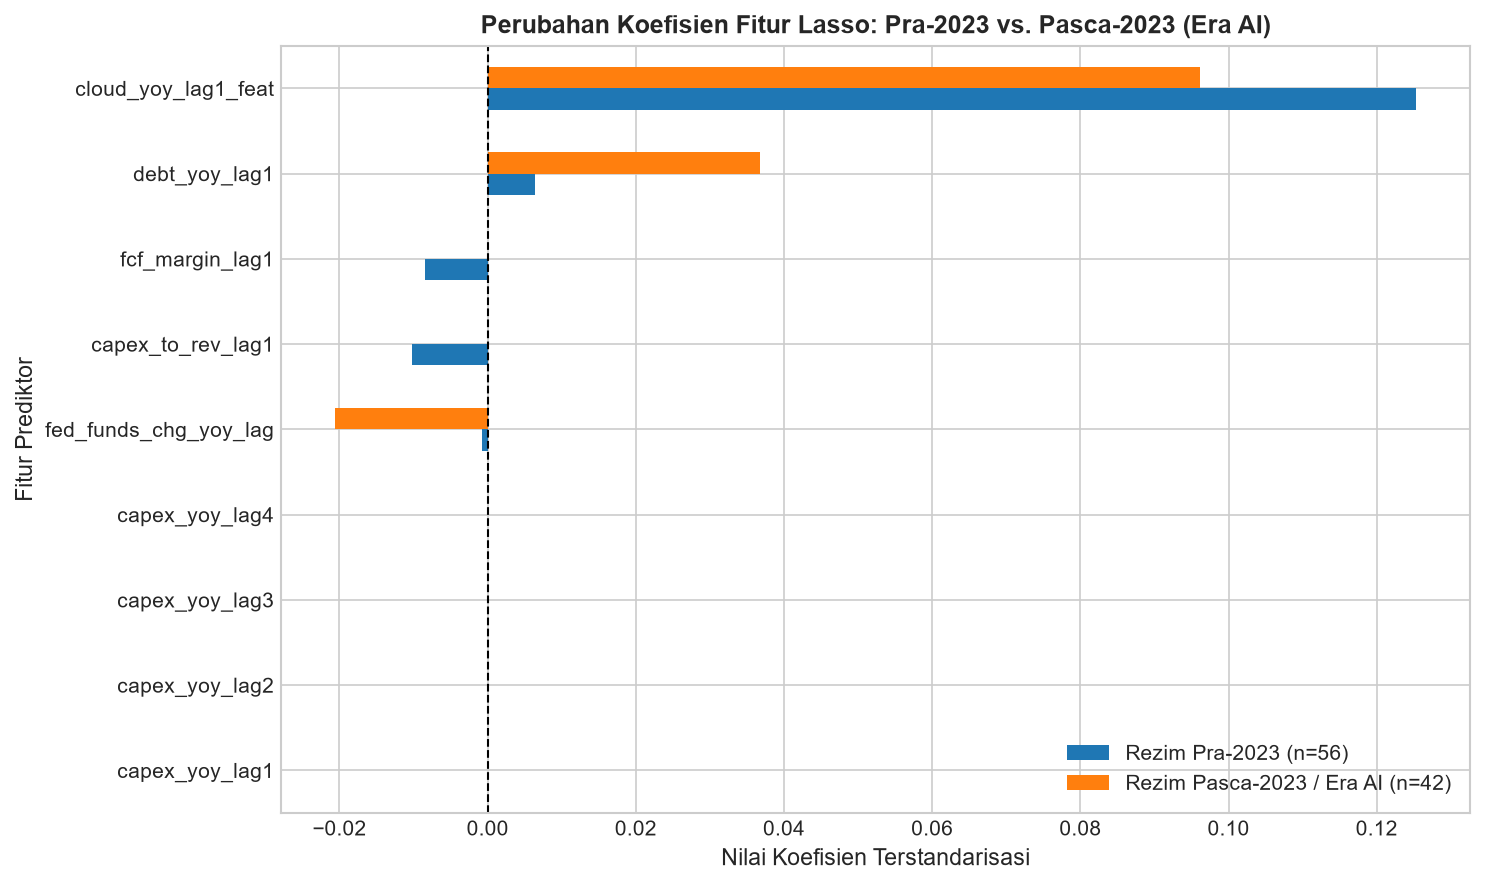

In [15]:
# ==============================================================================
# 13. EVALUASI KOEFISIEN LASSO PRA VS. PASCA 2023
# ==============================================================================
def fit_regime_lasso(df, cutoff=REGIME_CUTOFF):
    pre = df[df["period_end"] <= cutoff].dropna(subset=[TARGET] + FEATURES)
    post = df[df["period_end"] > cutoff].dropna(subset=[TARGET] + FEATURES)
    
    coef_data = {}
    for name, subset in [("Rezim Pra-2023 (n=56)", pre), ("Rezim Pasca-2023 / Era AI (n=42)", post)]:
        X = subset[FEATURES].to_numpy(dtype=float)
        y = subset[TARGET].to_numpy(dtype=float)
        scaler = StandardScaler().fit(X)
        alpha = tune_lasso_alpha(X, y)
        lasso = Lasso(alpha=alpha, max_iter=20000).fit(scaler.transform(X), y)
        coef_data[name] = dict(zip(FEATURES, lasso.coef_))
        
    return pd.DataFrame(coef_data)

df_coefs = fit_regime_lasso(df_cc)

print("=== KOEFISIEN TERSTANDARISASI LASSO: PRA-2023 VS. PASCA-2023 ===")
display(df_coefs.round(4))

# Plot Koefisien
df_coefs.plot(kind="barh", figsize=(10, 6), color=["#1f77b4", "#ff7f0e"])
plt.axvline(0, color="black", linestyle="--", lw=1)
plt.title("Perubahan Koefisien Fitur Lasso: Pra-2023 vs. Pasca-2023 (Era AI)", fontweight="bold")
plt.xlabel("Nilai Koefisien Terstandarisasi")
plt.ylabel("Fitur Prediktor")
plt.tight_layout()
plt.show()


---
## 14. Actionable Insights

Berdasarkan bukti empiris hasil pengujian model prediktif, kami merumuskan **tiga temuan kunci** dan **dua rekomendasi strategis konkret** bagi pemangku kepentingan (*C-Level Executive / CFO*):

### 14.1 Tiga Temuan Kunci Berbasis Bukti (*Evidence-Based Findings*)
1. **Temuan 1 (Kegagalan $H_1$ / Diskoneksi Capex ke Pendapatan Jangka Pendek)**:
   - Pertumbuhan belanja modal (*capex*) pada lag 1 hingga 4 kuartal memiliki **daya prediksi mendekati nol** terhadap pertumbuhan pendapatan cloud. Pada model Lasso, seluruh koefisien capex tereliminasi menjadi $0,000$. Korelasi silang (CCF) bersifat sangat lemah (AMZN: $\sim 0.09$) atau lebih bersifat bersamaan/kontemporer (GOOGL: $\sim 0.38$).
2. **Temuan 2 (Keunggulan Baseline Naive / Kegagalan $H_2$)**:
   - Model **Naive Persistence Baseline** (menggunakan pertumbuhan kuartal lalu) mengalahkan atau mengimbangi model-model machine learning kompleks untuk Amazon (RMSE: 0.0345 vs. 0.0975–0.1583) dan Google Cloud (RMSE: 0.0816 vs. 0.0887–0.1303). Pada Microsoft, model ML hanya memberikan keunggulan marjinal sekitar 5% (RMSE 0.0523 vs 0.0550). Penambahan variabel capex justru memicu estimasi *noise/overfitting* pada sampel kuartalan.
3. **Temuan 3 (Degradasi Model di Era AI / Pembuktian Sebagian $H_3$)**:
   - Model yang dilatih pada era pra-2023 mengalami lonjakan error drastis (RMSE memburuk 2x hingga 3x lipat) saat diuji pada era AI pasca-2023. Namun, kegagalan ini **bukan** karena capex menjadi prediktor yang lebih kuat, melainkan karena pergeseran volatilitas dan dinamika makroekonomi/suku bunga yang memengaruhi alokasi anggaran TI perusahaan klien.

---

### 14.2 Dua Rekomendasi Strategis yang Layak Diterapkan (*Feasible Recommendations*)

#### Rekomendasi 1: Dekoneksi Panduan Pendapatan Cloud dari Pengumuman Belanja Capex
- **Tindakan**: CFO, tim FP&A, dan analis riset ekuitas harus menghentikan praktik mengasumsikan bahwa pengumuman lonjakan belanja modal (*capex guidance*) secara otomatis menjadi sinyal akselerasi pertumbuhan pendapatan cloud dalam 1–4 kuartal ke depan.
- **Mekanisme Pelaksanaan**: Gunakan metrik komitmen kontrak (*Remaining Performance Obligations / RPO*) dan momentum organik sebagai dasar proyeksi top-line, bukan arus kas keluar untuk infrastruktur.
- **Mitigasi Risiko**: Mencegah *over-promising* panduan pendapatan kepada pasar yang berisiko memicu penurunan valuasi saham ketika pendapatan tidak langsung melonjak pasca-investasi pabrik server.

#### Rekomendasi 2: Terapkan Perencanaan Kapasitas Dinamis Berbasis Skenario Makro
- **Tindakan**: Komite Pengadaan Datacenter dan Alokasi Modal harus mengganti aturan konversi capex-ke-pendapatan yang kaku dengan **Model Skenario Bergulir (*Adaptive Autoregressive with Macro Buffers*)**.
- **Mekanisme Pelaksanaan**: Karena era pasca-2023 menunjukkan peningkatan sensitivitas terhadap suku bunga The Fed dan beban utang, komitmen kapasitas GPU harus dipecah menjadi modul-modul bertahap (*tranches*) dengan klausul fleksibilitas sewa guna usaha (*leasing option*) jika likuiditas pasar modal mengetat.


---
## 15. Implikasi Bisnis, Skenario 2030, dan Limitasi

### 15.1 Implikasi Praktis Organisasional
1. **Beban Depresiasi & Margin Gross**: Dengan percepatan siklus depresiasi server (4–6 tahun), pengeluaran belanja modal puluhan miliar dolar tanpa lonjakan pendapatan jangka pendek yang sepadan akan menekan margin kotor (*gross margin compression*). Perusahaan harus memonitor *Return on Invested Capital (ROIC)* secara ketat per klaster datacenter.
2. **Kapasitas Komersial vs. Konsumsi AI Internal**: Sebagian besar belanja modal AI diserap untuk kebutuhan internal emiten (misal: Meta Llama, Google Gemini, Microsoft Copilot) daripada disewakan langsung ke pelanggan. Pelaporan keuangan ke depan perlu memisahkan belanja infrastruktur *merchant cloud* vs *internal R&D*.

### 15.2 Latihan Skenario Jangka Panjang 2030 (Asumsi Eksplisit)
Karena model statistik membuktikan bahwa memproyeksikan deret waktu jauh ke depan menggunakan ekstrapolasi ML adalah tidak valid secara metodologis, kami menyajikan **latihan skenario berbasis compounding dengan asumsi transparan** (berangkat dari run-rate tahunan 2026):
- **Skenario Bear (Pertumbuhan 5% per tahun)**: Normalisasi belanja TI, komoditisasi GPU, dan perlambatan adopsi enterprise AI.
- **Skenario Base (Pertumbuhan 15% per tahun)**: Migrasi beban kerja komputasi awan yang stabil dan monetisasi AI bertahap.
- **Skenario Bull (Pertumbuhan 30% per tahun)**: Transformasi digital berbasis AI penuh dan ekspansi komputasi berdaulat (*sovereign cloud*).
- *Pita Ketidakpastian*: Pita ketidakpastian yang melebar secara linier $\pm 4\%$ per tahun untuk mencerminkan risiko perkiraan jangka panjang.

### 15.3 Limitasi Penelitian
- **Keterbatasan Ukuran Sampel**: Pelaporan segmen kuartalan menghasilkan sampel terbatas ($N \approx 20 - 40$ kuartal per emiten).
- **Agregasi Data Capex**: Pengungkapan publik 10-K/10-Q menggabungkan capex AI dengan peralatan kantor, tanah, dan datacenter konvensional.
- **Reklasifikasi Akuntansi**: Restrukturisasi segmen (seperti *recast* segmen Microsoft FY24) menciptakan diskontinuitas yang harus ditangani secara hati-hati.


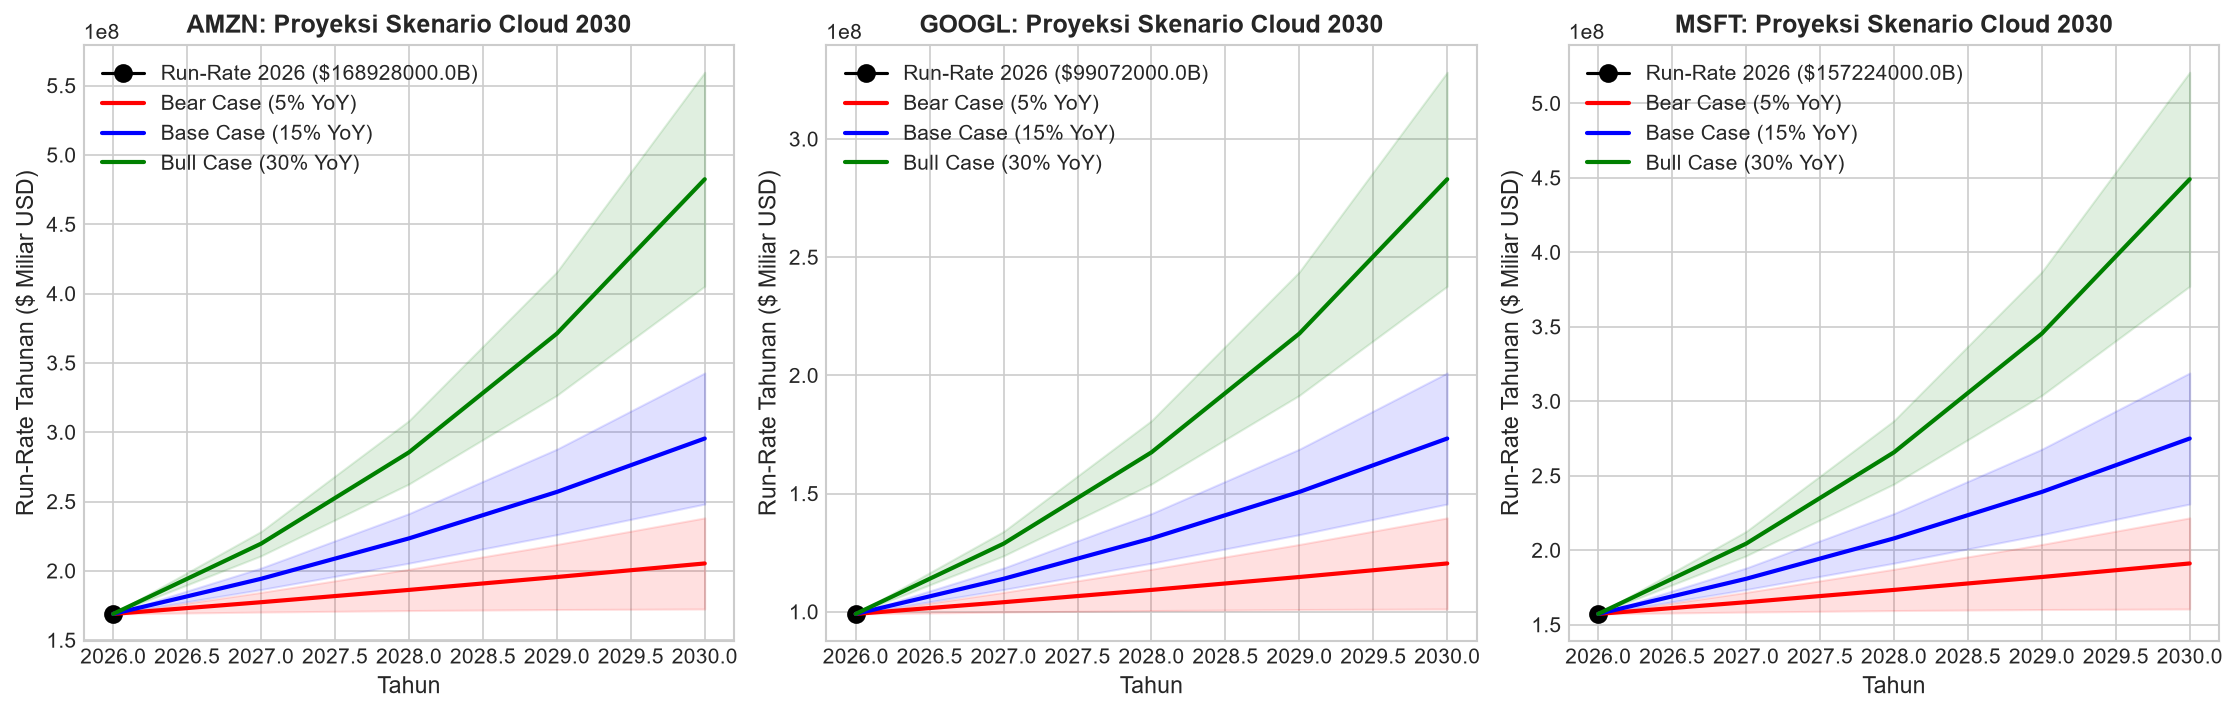

Skenario 2030 berhasil dibuat. Catatan: Latihan simulasi berbasis asumsi eksplisit, bukan ramalan pasti model machine learning.


In [16]:
# ==============================================================================
# 15. VISUALISASI SKENARIO RUN-RATE PENDAPATAN CLOUD TAHUN 2030
# ==============================================================================
def generate_2030_scenarios(df_panel):
    scenarios = {"Bear Case (5% YoY)": 0.05, "Base Case (15% YoY)": 0.15, "Bull Case (30% YoY)": 0.30}
    colors_scen = {"Bear Case (5% YoY)": "red", "Base Case (15% YoY)": "blue", "Bull Case (30% YoY)": "green"}
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=False)
    
    for idx, ticker in enumerate(tickers):
        sub = df_panel[df_panel["ticker"] == ticker].sort_values("period_end")
        last_row = sub.iloc[-1]
        last_date = last_row["period_end"]
        # Run-rate tahunan: kuartal terakhir * 4
        base_annual_rev = (last_row["cloud_revenue"] * 4) / 1e3 # dalam Miliar USD ($B)
        
        years = np.arange(last_date.year, 2031)
        
        axes[idx].plot([last_date.year], [base_annual_rev], marker="o", color="black", markersize=8, label=f"Run-Rate 2026 (${base_annual_rev:.1f}B)")
        
        for name, rate in scenarios.items():
            proj_curve = [base_annual_rev * ((1 + rate) ** (y - last_date.year)) for y in years]
            low_band = [val * (1 - 0.04 * (y - last_date.year)) for y, val in zip(years, proj_curve)]
            high_band = [val * (1 + 0.04 * (y - last_date.year)) for y, val in zip(years, proj_curve)]
            
            axes[idx].plot(years, proj_curve, label=name, color=colors_scen[name], lw=2)
            axes[idx].fill_between(years, low_band, high_band, color=colors_scen[name], alpha=0.12)
            
        axes[idx].set_title(f"{ticker}: Proyeksi Skenario Cloud 2030", fontweight="bold")
        axes[idx].set_ylabel("Run-Rate Tahunan ($ Miliar USD)")
        axes[idx].set_xlabel("Tahun")
        axes[idx].legend(loc="upper left")
        
    plt.tight_layout()
    plt.show()

generate_2030_scenarios(df_panel)
print("Skenario 2030 berhasil dibuat. Catatan: Latihan simulasi berbasis asumsi eksplisit, bukan ramalan pasti model machine learning.")
